# BRFSS 2024 — Diabetes EDA
**Question:** which demographic, behavioural and healthcare-access factors predict diabetes
among US adults? **Target:** `diabetes_status` (Yes / No diabetes / Pre-diabetes or borderline).
**Data:** CDC BRFSS 2024 annual file, 457,670 respondents.

This notebook follows the six-act EDA shape from lecture (Structure → Clean → Univariate →
Bivariate → Multivariate → **Decisions**). Every figure states the question it answers and
is followed by a short conclusion; the decision table at the end is what the modelling
stage builds on.


In [1]:
# Setup: silence warnings and use a clean, consistent plot style for every chart below.
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("plotting ready")


plotting ready


## Act 1 · Structure and cleaning
**Question:** what is actually in this file, and what is broken?
The deliverable is one verdict per column (table at the end of this act):
raw dtype, unit, reported vs true missing rate, and what we did about it.


In [2]:
# Load the raw CDC file (SAS XPORT): ~458k rows x 301 columns, the full 2024 LLCP release.
import pandas as pd


df = pd.read_sas("LLCP2024.XPT", format="xport")

In [3]:
# First look at the raw table: shape, dtypes and summary stats before touching anything.
print("Raw shape:", df.shape)
df.info()
print(df.describe().round(2).to_string())


Raw shape: (457670, 301)
<class 'pandas.DataFrame'>
RangeIndex: 457670 entries, 0 to 457669
Columns: 301 entries, _STATE to _AIDTST4
dtypes: float64(296), object(5)
memory usage: 1.0+ GB
          _STATE     FMONTH   DISPCODE          _PSU  CTELENM1  PVTRESD1  COLGHOUS  STATERE1  CELPHON1   LADULT1  NUMADULT  RESPSLC1  LANDSEX3  SAFETIME  CTELNUM1  CELLFON5   CADULT1   CELLSEX3   PVTRESD3  CCLGHOUS    CSTATE1   LANDLINE    HHADULT     SEXVAR    GENHLTH   PHYSHLTH   MENTHLTH   POORHLTH   PRIMINS2   PERSDOC3   MEDCOST1   CHECKUP1   EXERANY2   LASTDEN4   RMVTETH4   CVDINFR4   CVDCRHD4   CVDSTRK3    ASTHMA3   ASTHNOW   CHCSCNC1   CHCOCNC1   CHCCOPD3   ADDEPEV3   CHCKDNY2   HAVARTH4   DIABETE4  DIABAGE4    MARITAL      EDUCA   RENTHOM1  NUMHHOL4  NUMPHON4   CPDEMO1C   VETERAN3    EMPLOY1   CHILDREN    INCOME3  PREGNANT    WEIGHT2    HEIGHT3       DEAF      BLIND     DECIDE   DIFFWALK   DIFFDRES   DIFFALON     HADMAM    HOWLONG   CERVSCRN   CRVCLCNC   CRVCLPAP   CRVCLHPV   HADHYST2   HADSIGM

In [4]:
# List every raw column so we can see the full 301-variable codebook before selecting.
for column in df.columns:
    print(column, ":", df[column].dtype)

_STATE : float64
FMONTH : float64
IDATE : object
IMONTH : object
IDAY : object
IYEAR : object
DISPCODE : float64
SEQNO : object
_PSU : float64
CTELENM1 : float64
PVTRESD1 : float64
COLGHOUS : float64
STATERE1 : float64
CELPHON1 : float64
LADULT1 : float64
NUMADULT : float64
RESPSLC1 : float64
LANDSEX3 : float64
SAFETIME : float64
CTELNUM1 : float64
CELLFON5 : float64
CADULT1 : float64
CELLSEX3 : float64
PVTRESD3 : float64
CCLGHOUS : float64
CSTATE1 : float64
LANDLINE : float64
HHADULT : float64
SEXVAR : float64
GENHLTH : float64
PHYSHLTH : float64
MENTHLTH : float64
POORHLTH : float64
PRIMINS2 : float64
PERSDOC3 : float64
MEDCOST1 : float64
CHECKUP1 : float64
EXERANY2 : float64
LASTDEN4 : float64
RMVTETH4 : float64
CVDINFR4 : float64
CVDCRHD4 : float64
CVDSTRK3 : float64
ASTHMA3 : float64
ASTHNOW : float64
CHCSCNC1 : float64
CHCOCNC1 : float64
CHCCOPD3 : float64
ADDEPEV3 : float64
CHCKDNY2 : float64
HAVARTH4 : float64
DIABETE4 : float64
DIABAGE4 : float64
MARITAL : float64
EDUCA : floa

In [5]:
# Find repeat response rows: identical answers across every column except the ID/weight columns.
cols = df.columns.difference(['SEQNO', '_PSU'])

duplicate_rows = df[df.duplicated(subset=cols, keep=False)]

groups = duplicate_rows.groupby(list(cols), dropna=False)

print("Total duplicate rows:", len(duplicate_rows))
print("Total duplicate groups:", len(groups))

Total duplicate rows: 56
Total duplicate groups: 28


In [6]:
# Drop the duplicates, keeping the first row of each identical-answer group.
cols = df.columns.difference(['SEQNO', '_PSU'])

df = df.drop_duplicates(subset=cols, keep='first')

print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 457642


In [7]:
# Columns excluded from analysis (IDs, weights, and variables the group chose to drop).
ignore_cols = [
    'SEQNO',
    '_PSU',
    '_STATE',
    'FMONTH',
    'IDATE',
    'IMONTH',
    'IDAY',
    'IYEAR',
    'DISPCODE',
    'QSTVER',
    'QSTLANG'
]

past_30_day_cols = [
    'PHYSHLTH',
    'MENTHLTH',
    'POORHLTH',
    'ALCDAY4'
]

ignore_cols += past_30_day_cols
ignore_cols = [c for c in ignore_cols if c in df.columns]

person_cols = [c for c in df.columns if c not in ignore_cols]

df['_INTERVIEW_DATE'] = pd.to_datetime(
    df['IYEAR'].astype(str) + '-' +
    df['IMONTH'].astype(str) + '-' +
    df['IDAY'].astype(str),
    errors='coerce'
)

duplicates = df[
    df.duplicated(
        subset=person_cols,
        keep=False
    )
]

count = 0

for _, group in duplicates.groupby(person_cols, dropna=False):

    if group['_INTERVIEW_DATE'].nunique() > 1:
        count += 1

        print(f"\n{'='*30} POSSIBLE REPEAT {count} {'='*30}")

        print(
            group[
                ['SEQNO', '_INTERVIEW_DATE']
            ].sort_values('_INTERVIEW_DATE').to_string(index=False)
        )

print("\nPotential repeat groups:", count)


============================== POSSIBLE REPEAT 1 ==============================
        SEQNO _INTERVIEW_DATE
b'2024009388'      2024-10-18
b'2024008556'      2024-10-19

Potential repeat groups: 1


In [8]:
# The three 'past 30 days' alcohol questions — helpers for recovering structural zeros later.
past_30_day_cols = [
    'PHYSHLTH',
    'MENTHLTH',
    'POORHLTH',
    'ALCDAY4'
]

for i, (_, group) in enumerate(
    duplicates.groupby(person_cols, dropna=False),
    start=1
):
    if group['_INTERVIEW_DATE'].nunique() > 1:
        print(f"\n{'='*30} POSSIBLE REPEAT {i} {'='*30}")

        print(
            group[
                ['SEQNO', '_INTERVIEW_DATE'] + past_30_day_cols
            ].sort_values('_INTERVIEW_DATE').to_string(index=False)
        )


============================== POSSIBLE REPEAT 1 ==============================
        SEQNO _INTERVIEW_DATE  PHYSHLTH  MENTHLTH  POORHLTH  ALCDAY4
b'2024009388'      2024-10-18      88.0      88.0       NaN    888.0
b'2024008556'      2024-10-19      88.0      88.0       NaN    888.0


In [9]:
# Remove the one repeat respondent (the same person interviewed twice).
df = df[df['SEQNO'] != b'2024008556']

In [51]:
# Keep the 36 columns: target + 34 features + 2 cleaning helpers.
selected_cols = [
    "DIABETE4",
    "EXERANY2",
    "_TOTINDA",
    "WEIGHT2",
    "_BMI5",
    "_BMI5CAT",
    "SMOKE100",
    "_SMOKER3",
    "USENOW3",
    "ECIGNOW3",
    "LCSNUMCG",
    "_PACKYRS",
    "_LCSYQTS",
    "ALCDAY4",
    "DRNK3GE5",
    "DRNKANY6",
    "_DRNKWK3",
    "_RFDRHV9",
    "SSBSUGR2",
    "SSBFRUT3",
    "SEXVAR",
    "_AGE80",
    "_AGEG5YR",
    "EDUCA",
    "INCOME3",
    "_INCOMG1",
    "MARITAL",
    "EMPLOY1",
    "_RACEGR3",
    "GENHLTH",
    "POORHLTH",
    "CVDSTRK3",
    "PHYSHLTH",
    "MENTHLTH",
    "PDIABTS1",
    "CHECKUP1"
]

df = df[selected_cols].copy()

print("Number of columns:", len(df.columns))
print(df.columns.tolist())


KeyError: "None of [Index(['DIABETE4', 'EXERANY2', '_TOTINDA', 'WEIGHT2', '_BMI5', '_BMI5CAT',\n       'SMOKE100', '_SMOKER3', 'USENOW3', 'ECIGNOW3', 'LCSNUMCG', '_PACKYRS',\n       '_LCSYQTS', 'ALCDAY4', 'DRNK3GE5', 'DRNKANY6', '_DRNKWK3', '_RFDRHV9',\n       'SSBSUGR2', 'SSBFRUT3', 'SEXVAR', '_AGE80', '_AGEG5YR', 'EDUCA',\n       'INCOME3', '_INCOMG1', 'MARITAL', 'EMPLOY1', '_RACEGR3', 'GENHLTH',\n       'POORHLTH', 'CVDSTRK3', 'PHYSHLTH', 'MENTHLTH', 'PDIABTS1', 'CHECKUP1'],\n      dtype='str')] are in the [columns]"

Corrected missing percentages:
_AGE80       0.00
SEXVAR       0.00
DIABETE4     0.23
GENHLTH      0.29
EXERANY2     0.29
_TOTINDA     0.29
CVDSTRK3     0.32
EDUCA        0.52
MARITAL      0.92
CHECKUP1     1.17
POORHLTH     1.24
_AGEG5YR     1.82
EMPLOY1      1.84
_RACEGR3     1.99
USENOW3      6.70
SMOKE100     6.88
_SMOKER3     7.00
ECIGNOW3     7.15
LCSNUMCG     7.60
WEIGHT2      7.95
_BMI5CAT     9.40
_BMI5        9.40
DRNKANY6     9.56
ALCDAY4      9.56
_RFDRHV9    10.20
_DRNKWK3    10.29
DRNK3GE5    10.36
_PACKYRS    12.62
INCOME3     19.10
_INCOMG1    19.10
PDIABTS1    67.11
SSBSUGR2    74.74
SSBFRUT3    74.80
_LCSYQTS    75.44


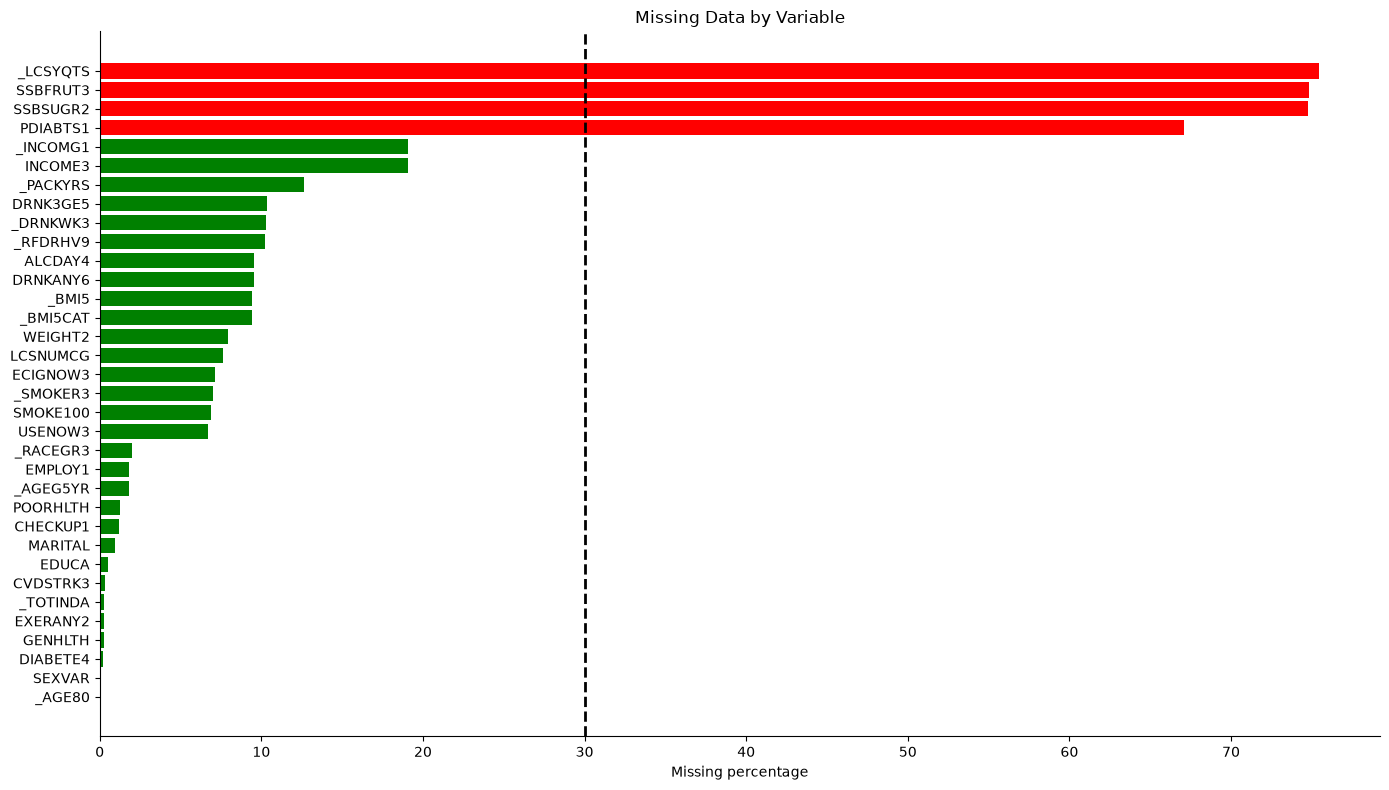


Dropped columns:
['PDIABTS1', 'SSBSUGR2', 'SSBFRUT3', '_LCSYQTS']

Remaining columns:
['DIABETE4', 'EXERANY2', '_TOTINDA', 'WEIGHT2', '_BMI5', '_BMI5CAT', 'SMOKE100', '_SMOKER3', 'USENOW3', 'ECIGNOW3', 'LCSNUMCG', '_PACKYRS', 'ALCDAY4', 'DRNK3GE5', 'DRNKANY6', '_DRNKWK3', '_RFDRHV9', 'SEXVAR', '_AGE80', '_AGEG5YR', 'EDUCA', 'INCOME3', '_INCOMG1', 'MARITAL', 'EMPLOY1', '_RACEGR3', 'GENHLTH', 'POORHLTH', 'CVDSTRK3', 'CHECKUP1']


In [11]:
import numpy as np
import matplotlib.pyplot as plt


missing_codes = {
    "DIABETE4": [7, 9],
    "EXERANY2": [7, 9],
    "_TOTINDA": [9],
    "WEIGHT2": [7777, 9999],
    "_BMI5": [9999],
    "SMOKE100": [7, 9],
    "_SMOKER3": [9],
    "USENOW3": [7, 9],
    "ECIGNOW3": [7, 9],
    "ALCDAY4": [777, 999, 100],
    "LCSNUMCG": [777, 999],
    "DRNK3GE5": [77, 99],
    "DRNKANY6": [7, 9],
    "_DRNKWK3": [99900],
    "_RFDRHV9": [9],
    "_AGEG5YR": [14],
    "EDUCA": [9],
    "INCOME3": [77, 99],
    "_INCOMG1": [9],
    "MARITAL": [9],
    "EMPLOY1": [9],             
    "_RACEGR3": [9],
    "GENHLTH": [7, 9],
    "POORHLTH": [77, 99],       
    "CVDSTRK3": [7, 9],
    "PDIABTS1": [7, 9],
    "CHECKUP1": [7, 9]
}


for col, codes in missing_codes.items():
    if col in df.columns:
        df.loc[df[col].isin(codes), col] = np.nan

# --- SAS special missings: read_sas leaves bit-patterns like 5.4e-79 as tiny doubles
# instead of NaN (verified: 203k rows in _DRNKWK3, 6k in _PACKYRS). No real answer in
# these integer-coded columns is < 1e-10, so map the garbage to NaN before anything else.
for _c in df.select_dtypes(include="number").columns:
    df.loc[(df[_c] > 0) & (df[_c] < 1e-10), _c] = np.nan

# --- Audit snapshot: remember which cells were missing BEFORE any filling ---
# The "does filling distort the target?" check later compares filled vs observed rows.
was_missing = df.isna().copy()

# --- Structural missingness: the survey skips questions that don't apply ---
# POORHLTH is only asked after >=1 poor-health day (PHYSHLTH/MENTHLTH);
# 88 = "None" = 0 days limited. Verified: 100% of missing POORHLTH sits in
# the PHYSHLTH=88 & MENTHLTH=88 cell, so missing -> 0 recovers ~189k rows.
df.loc[df["POORHLTH"] == 88, "POORHLTH"] = 0
no_poor_days = (df["PHYSHLTH"] == 88) & (df["MENTHLTH"] == 88)
df.loc[no_poor_days & df["POORHLTH"].isna(), "POORHLTH"] = 0
df = df.drop(columns=["PHYSHLTH", "MENTHLTH"])  # helpers only, not features
# Smoking intensity was only asked of ever-smokers: never-smokers truly had 0
df.loc[df["_SMOKER3"].isin([3, 4]) & df["LCSNUMCG"].isna(), "LCSNUMCG"] = 0
df.loc[(df["_SMOKER3"] == 4) & df["_PACKYRS"].isna(), "_PACKYRS"] = 0
# Binge occasions only asked of drinkers; 88 = "None" = 0 occasions
df.loc[df["DRNK3GE5"] == 88, "DRNK3GE5"] = 0
df.loc[(df["DRNKANY6"] == 2) & df["DRNK3GE5"].isna(), "DRNK3GE5"] = 0
# A non-drinker truly has 0 drinks/week (their _DRNKWK3 was SAS special-missing, now NaN)
df.loc[(df["DRNKANY6"] == 2) & df["_DRNKWK3"].isna(), "_DRNKWK3"] = 0

missing_pct = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=True)
)

print("Corrected missing percentages:")
print(missing_pct.round(2).to_string())

colors = ["green" if value <= 30 else "red"
           for value in missing_pct.values]

plt.figure(figsize=(14, 8))
plt.barh(missing_pct.index, missing_pct.values, color=colors)
plt.axvline(30, color="black", linestyle="--", linewidth=2)
plt.xlabel("Missing percentage")
plt.title("Missing Data by Variable")
plt.tight_layout()
plt.show()

columns_to_drop = missing_pct[missing_pct > 30].index.tolist()

df = df.drop(columns=columns_to_drop)

print("\nDropped columns:")
print(columns_to_drop)

print("\nRemaining columns:")
print(df.columns.tolist())


### Target construction — a decision, not a default
`DIABETE4`: 1 → **Yes**; 3 → **No diabetes**; 2 = gestational-only → folded into
**No diabetes** (pregnancy-only condition, n≈3.4k, not the chronic disease we model);
4 = pre-diabetes → kept as its own class. Codes 7/9 (don't know/refused) are dropped —
the target is never imputed.
**Consequence:** this is a 3-class problem, so the ML direction is multiclass
classification (with resampling for the minority classes), not binary.


In [12]:
# Build the 3-class target: keep valid diabetes answers, drop don't-know / refused / missing.
df = df[df["DIABETE4"].isin([1, 2, 3, 4])].copy()
was_missing = was_missing.loc[df.index]  # keep audit rows aligned
df["DIABETE4"] = df["DIABETE4"].replace({
    1: 1,
    2: 2,
    3: 2,
    4: 3
}).astype(int)

print(df["DIABETE4"].value_counts().sort_index())
print("\nClass balance (%):")
print((df["DIABETE4"].value_counts(normalize=True).sort_index() * 100).round(2))


DIABETE4
1     65797
2    379485
3     11305
Name: count, dtype: int64

Class balance (%):
DIABETE4
1    14.41
2    83.11
3     2.48
Name: proportion, dtype: float64


In [13]:
# Unit fixes: metric weights (9000s) -> pounds; BMI and drinks/week are stored x100.
metric_rows = df["WEIGHT2"].between(9000, 9998)

df.loc[metric_rows, "WEIGHT2"] = (
    df.loc[metric_rows, "WEIGHT2"] - 9000
) * 2.20462

df["_BMI5"] = df["_BMI5"] / 100
df["_DRNKWK3"] = df["_DRNKWK3"] / 100  # stored x100, 2 implied decimals

weekly_rows = df["ALCDAY4"].between(101, 199)
monthly_rows = df["ALCDAY4"].between(201, 299)
no_drink_rows = df["ALCDAY4"] == 888

df.loc[weekly_rows, "ALCDAY4"] = (
    df.loc[weekly_rows, "ALCDAY4"] - 100
) * (30 / 7)

df.loc[monthly_rows, "ALCDAY4"] = (
    df.loc[monthly_rows, "ALCDAY4"] - 200
)

df.loc[no_drink_rows, "ALCDAY4"] = 0
df["ALCDAY4"] = df["ALCDAY4"].round(0)  # whole days; weekly->monthly math gives 4.2857 etc.

numeric_cols = [
    "WEIGHT2",
    "_BMI5",
    "ALCDAY4",
    "_DRNKWK3",
    "_AGE80",
    "POORHLTH",
    "LCSNUMCG",
    "_PACKYRS",
    "DRNK3GE5"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

categorical_cols = [
    col for col in df.columns
    if col not in numeric_cols + ["DIABETE4"]
]

for col in categorical_cols:
    df[col] = (
        df[col]
        .astype("string")
        .fillna("Unknown")
    )

print("Remaining null values in df:",
      df.isna().sum().sum())


Remaining null values in df: 0


In [14]:
# Decode every categorical code to its label (e.g. 1 -> 'Yes') and give columns friendly names.
value_maps = {
    "DIABETE4": {
        "1": "Yes",
        "2": "No diabetes",
        "3": "Pre-diabetes or borderline",
        "7": "Unknown",
        "9": "Unknown"
    },
    "EXERANY2": {"1": "Yes", "2": "No", "7": "Unknown", "9": "Unknown"},
    "_TOTINDA": {"1": "Yes", "2": "No", "7": "Unknown", "9": "Unknown"},
    "_BMI5CAT": {
        "1": "Underweight",
        "2": "Normal weight",
        "3": "Overweight",
        "4": "Obese",
        "9": "Unknown"
    },
    "SMOKE100": {"1": "Yes", "2": "No", "7": "Unknown", "9": "Unknown"},
    "_SMOKER3": {
        "1": "Current smoker - every day",
        "2": "Current smoker - some days",
        "3": "Former smoker",
        "4": "Never smoker",
        "9": "Unknown"
    },
    "USENOW3": {
        "1": "Every day",
        "2": "Some days",
        "3": "Not at all",
        "7": "Unknown",
        "9": "Unknown"
    },
    "ECIGNOW3": {
        "1": "Never used",
        "2": "Every day",
        "3": "Some days",
        "4": "Used in the past, not currently",
        "7": "Unknown",
        "9": "Unknown"
    },
    "DRNKANY6": {"1": "Yes", "2": "No", "7": "Unknown", "9": "Unknown"},
    "_RFDRHV9": {"1": "No", "2": "Yes", "7": "Unknown", "9": "Unknown"},
    "SEXVAR": {"1": "Male", "2": "Female"},
    "_AGEG5YR": {
        "1": "18-24",
        "2": "25-29",
        "3": "30-34",
        "4": "35-39",
        "5": "40-44",
        "6": "45-49",
        "7": "50-54",
        "8": "55-59",
        "9": "60-64",
        "10": "65-69",
        "11": "70-74",
        "12": "75-79",
        "13": "80+",
        "14": "Unknown"
    },
    "EDUCA": {
        "1": "Never attended school or kindergarten",
        "2": "Elementary school",
        "3": "Some high school",
        "4": "High school graduate or GED",
        "5": "Some college or technical school",
        "6": "College graduate",
        "9": "Unknown"
    },
    "INCOME3": {
        "1": "Less than $10,000",
        "2": "$10,000 to less than $15,000",
        "3": "$15,000 to less than $20,000",
        "4": "$20,000 to less than $25,000",
        "5": "$25,000 to less than $35,000",
        "6": "$35,000 to less than $50,000",
        "7": "$50,000 to less than $75,000",
        "8": "$75,000 to less than $100,000",
        "9": "$100,000 to less than $150,000",
        "10": "$150,000 to less than $200,000",
        "11": "$200,000 or more",
        "77": "Unknown",
        "99": "Unknown"
    },
    "_INCOMG1": {
        "1": "Less than $15,000",
        "2": "$15,000 to less than $25,000",
        "3": "$25,000 to less than $35,000",
        "4": "$35,000 to less than $50,000",
        "5": "$50,000 to less than $100,000",
        "6": "$100,000 to less than $200,000",
        "7": "$200,000 or more",
        "9": "Unknown"
    },
    "MARITAL": {
        "1": "Married",
        "2": "Divorced",
        "3": "Widowed",
        "4": "Separated",
        "5": "Never married",
        "6": "Unmarried couple",
        "9": "Unknown"
    },
    "EMPLOY1": {
        "1": "Employed for wages",
        "2": "Self-employed",
        "3": "Out of work for one year or more",
        "4": "Out of work for less than one year",
        "5": "Homemaker",
        "6": "Student",
        "7": "Retired",
        "8": "Unable to work",
        "9": "Unknown"
    },
    "_RACEGR3": {
        "1": "White, non-Hispanic",
        "2": "Black, non-Hispanic",
        "3": "Other, non-Hispanic",
        "4": "Multiracial, non-Hispanic",
        "5": "Hispanic",
        "9": "Unknown"
    },
    "GENHLTH": {
        "1": "Excellent",
        "2": "Very good",
        "3": "Good",
        "4": "Fair",
        "5": "Poor",
        "7": "Unknown",
        "9": "Unknown"
    },
    "CVDSTRK3": {"1": "Yes", "2": "No", "7": "Unknown", "9": "Unknown"},
    "CHECKUP1": {
        "1": "Within the past year",
        "2": "Within the past two years",
        "3": "Within the past five years",
        "4": "Five or more years ago",
        "8": "Never",
        "7": "Unknown",
        "9": "Unknown"
    }
}

for column, mapping in value_maps.items():
    if column in df.columns:
        values = df[column].astype("string").str.replace(r"\.0$", "", regex=True)
        df[column] = values.replace(mapping).fillna("Unknown")

rename_map = {
    "DIABETE4": "diabetes_status",
    "EXERANY2": "physical_activity",
    "_TOTINDA": "leisure_physical_activity",
    "WEIGHT2": "weight_pounds",
    "_BMI5": "bmi",
    "_BMI5CAT": "bmi_category",
    "SMOKE100": "smoked_100_cigarettes",
    "_SMOKER3": "smoking_status",
    "USENOW3": "smokeless_tobacco_use",
    "ECIGNOW3": "e_cigarette_use",
    "ALCDAY4": "alcohol_days_per_month",
    "DRNKANY6": "alcohol_use_past_30_days",
    "_DRNKWK3": "alcohol_drinks_per_week",
    "_RFDRHV9": "heavy_alcohol_use",
    "SEXVAR": "gender",
    "_AGE80": "age",
    "_AGEG5YR": "age_group",
    "EDUCA": "education_level",
    "INCOME3": "detailed_income_level",
    "_INCOMG1": "income_group",
    "MARITAL": "marital_status",
    "EMPLOY1": "employment_status",
    "_RACEGR3": "race_ethnicity",
    "GENHLTH": "general_health",
    "CVDSTRK3": "stroke_history",
    "POORHLTH": "poor_health_days",
    "LCSNUMCG": "cigarettes_per_day",
    "_PACKYRS": "pack_years",
    "DRNK3GE5": "binge_drinking_occasions",
    "CHECKUP1": "routine_checkup"
}

df.rename(columns=rename_map, inplace=True)


In [15]:
# Second look: shape, dtypes and stats on the CLEANED table, confirming the fixes landed.
print("Cleaned shape:", df.shape)
df.info()
print(df.describe().round(2).to_string())


Cleaned shape: (456587, 30)
<class 'pandas.DataFrame'>
Index: 456587 entries, 0 to 457669
Data columns (total 30 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   diabetes_status            456587 non-null  string 
 1   physical_activity          456587 non-null  string 
 2   leisure_physical_activity  456587 non-null  string 
 3   weight_pounds              456587 non-null  float64
 4   bmi                        456587 non-null  float64
 5   bmi_category               456587 non-null  string 
 6   smoked_100_cigarettes      456587 non-null  string 
 7   smoking_status             456587 non-null  string 
 8   smokeless_tobacco_use      456587 non-null  string 
 9   e_cigarette_use            456587 non-null  string 
 10  cigarettes_per_day         456587 non-null  float64
 11  pack_years                 456587 non-null  float64
 12  alcohol_days_per_month     456587 non-null  float64
 13  binge_drinking_oc

### Does filling nulls distort the target? — one check per column
**Question:** for each filled column, does the diabetes percentage change when we go from
"originally-observed rows only" to "everything after filling"? Each snippet below draws the
same graph twice — **left** on observed rows only, **right** on all rows (filled + original).
If a column's percentages jump, reconsider its filling technique (median? zero? "Unknown"?
or drop the column). `was_missing` was snapshotted before any filling, so "observed" here
means truly observed.


In [16]:
# Audit setup: helper that draws observed-vs-filled diabetes-% bars for one column.
import numpy as np
is_yes = (df["diabetes_status"] == "Yes").astype(int)

def audit_fig(col, old, bins=None, labels=None, fill_how=""):
    """Draw P(diabetes) by bin/category twice: observed-only rows vs all rows after filling."""
    filled = was_missing[old]
    n_fill = int(filled.sum())
    if n_fill == 0:
        print(f"{col}: nothing was filled — nothing to audit.")
        return
    yo, ya = is_yes[~filled], is_yes
    if bins is not None:  # numeric column -> bin it identically on both sides
        bo = pd.cut(df.loc[~filled, col], bins=bins, labels=labels, include_lowest=True)
        ba = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
        r1 = (yo.groupby(bo, observed=True).mean() * 100).reindex(labels)
        r2 = (ya.groupby(ba, observed=True).mean() * 100).reindex(labels)
        n1 = bo.value_counts().reindex(labels)
        n2 = ba.value_counts().reindex(labels)
        cats = labels
    else:  # categorical column -> "Unknown" appears only on the right
        r1 = (yo.groupby(df.loc[~filled, col], observed=True).mean() * 100)
        r2 = (ya.groupby(df[col], observed=True).mean() * 100)
        cats = r2.index.tolist()
        r1, n1 = r1.reindex(cats), df.loc[~filled, col].value_counts().reindex(cats)
        n2 = df[col].value_counts().reindex(cats)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, r, n, tag in zip(axes, [r1, r2], [n1, n2],
                             ["BEFORE — observed rows only", "AFTER — filled + original"]):
        x = range(len(cats))
        ax.bar(x, [0 if np.isnan(v) else v for v in r.values], color="#2C6E9B")
        for k, (v, c_) in enumerate(zip(r.values, n.values)):
            lab = f"{v:.1f}%\n(n={int(c_):,})" if not np.isnan(v) else "n/a"
            ax.text(k, (v if not np.isnan(v) else 0) + 0.5, lab,
                    ha="center", fontsize=7.5)
        ax.set_xticks(list(x))
        ax.set_xticklabels(cats, fontsize=8, rotation=20, ha="right")
        ax.set_title(tag, fontsize=10, loc="left")
        ax.set_ylabel("% with diabetes")
    top = max(np.nanmax(r1.values), np.nanmax(r2.values))
    axes[0].set_ylim(0, top * 1.45)  # headroom for the labels
    fig.suptitle(f"Fill audit — {col}  ({fill_how}; {n_fill:,} rows filled, {n_fill/len(df):.1%})",
                 fontsize=12, x=0.02, ha="left")
    plt.tight_layout(pad=1.5, rect=[0, 0, 1, 0.94])
    plt.show()
    chg = float((r2 - r1).abs().max())
    print(f"Largest bin change after filling: {chg:.2f} percentage points")
    if chg < 3:
        print("Verdict: the fill barely moves any bin — safe to keep this technique.")
    else:
        print("Verdict: some bins moved — check whether the filled group is structurally")
        print("different (e.g. non-drinkers) before changing the filling technique.")
print("audit helper ready")


audit helper ready


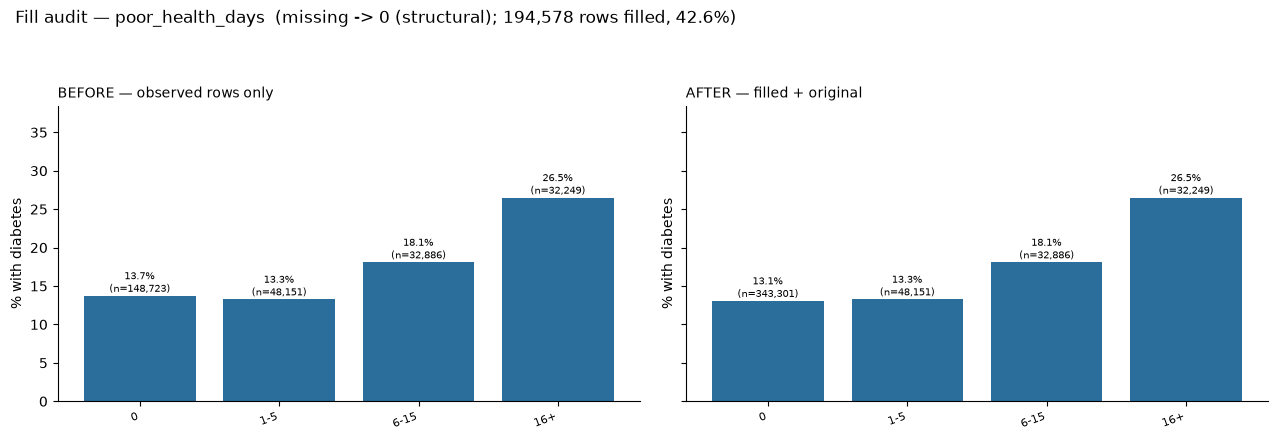

Largest bin change after filling: 0.67 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [17]:
# poor_health_days — structural fill: missing -> 0 (only asked after >=1 bad-health day)
audit_fig("poor_health_days", "POORHLTH", bins=[0, 1, 6, 16, np.inf],
          labels=["0", "1-5", "6-15", "16+"], fill_how="missing -> 0 (structural)")


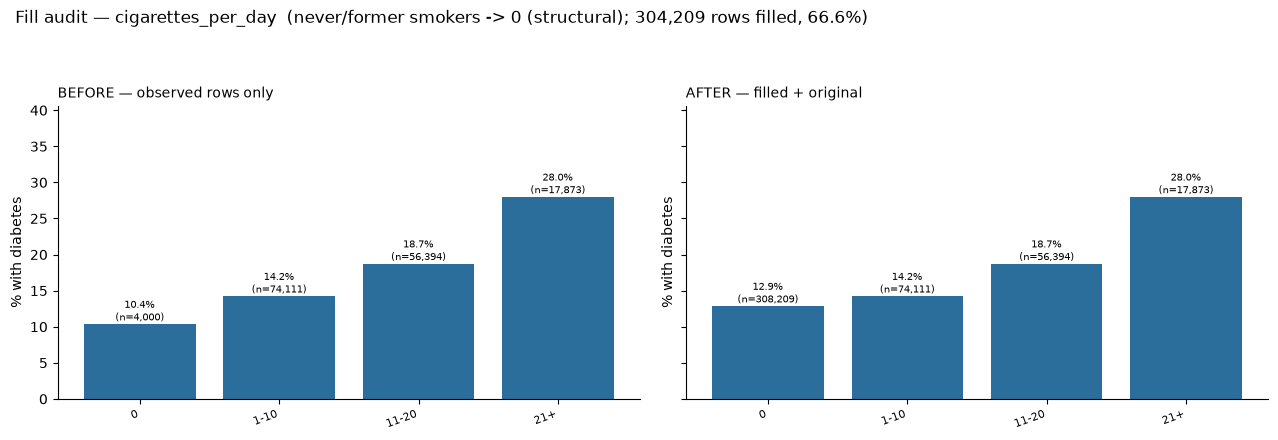

Largest bin change after filling: 2.49 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [18]:
# cigarettes_per_day — structural fill: never/former smokers -> 0
audit_fig("cigarettes_per_day", "LCSNUMCG", bins=[0, 1, 11, 21, np.inf],
          labels=["0", "1-10", "11-20", "21+"], fill_how="never/former smokers -> 0 (structural)")


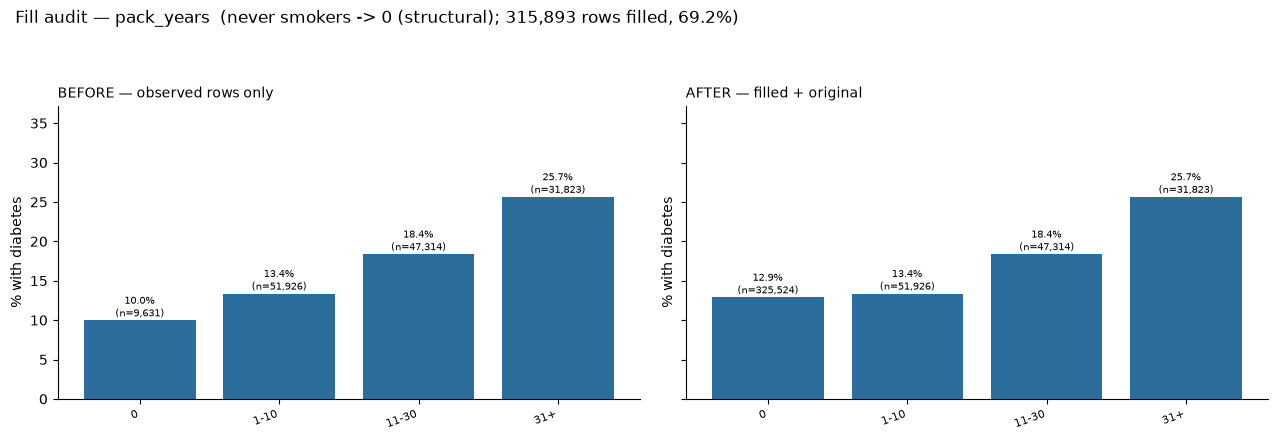

Largest bin change after filling: 2.92 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [19]:
# pack_years — structural fill: never smokers -> 0
audit_fig("pack_years", "_PACKYRS", bins=[0, 1, 11, 31, np.inf],
          labels=["0", "1-10", "11-30", "31+"], fill_how="never smokers -> 0 (structural)")


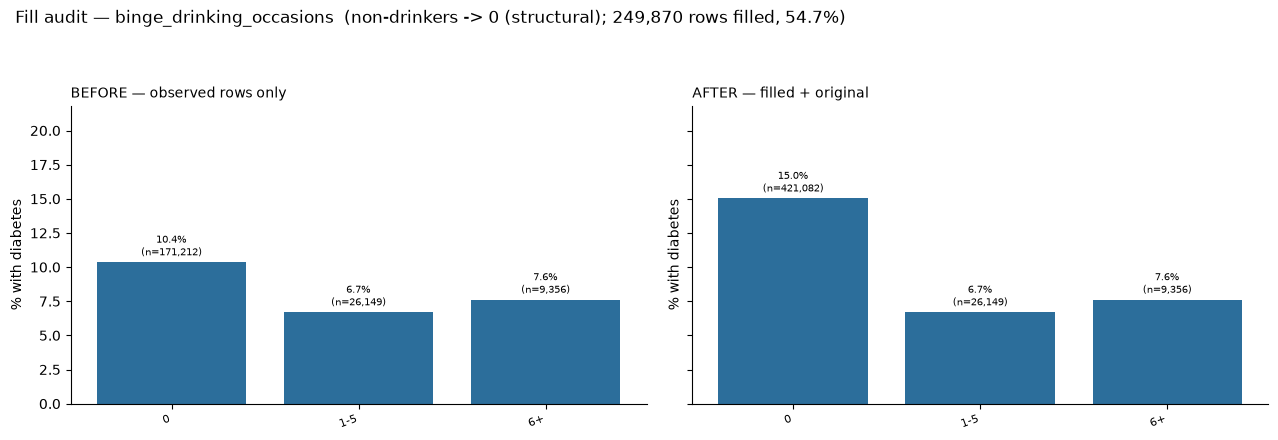

Largest bin change after filling: 4.67 percentage points
Verdict: some bins moved — check whether the filled group is structurally
different (e.g. non-drinkers) before changing the filling technique.


In [20]:
# binge_drinking_occasions — structural fill: non-drinkers -> 0 (88 = "None")
audit_fig("binge_drinking_occasions", "DRNK3GE5", bins=[0, 1, 6, np.inf],
          labels=["0", "1-5", "6+"], fill_how="non-drinkers -> 0 (structural)")


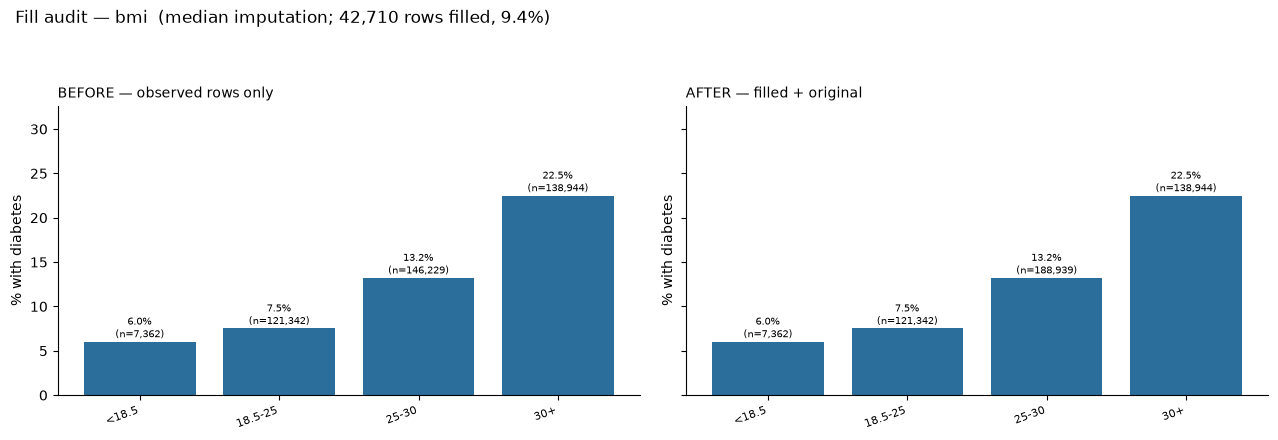

Largest bin change after filling: 0.00 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [21]:
# bmi — median imputation (skewed variable)
audit_fig("bmi", "_BMI5", bins=[0, 18.5, 25, 30, np.inf],
          labels=["<18.5", "18.5-25", "25-30", "30+"], fill_how="median imputation")


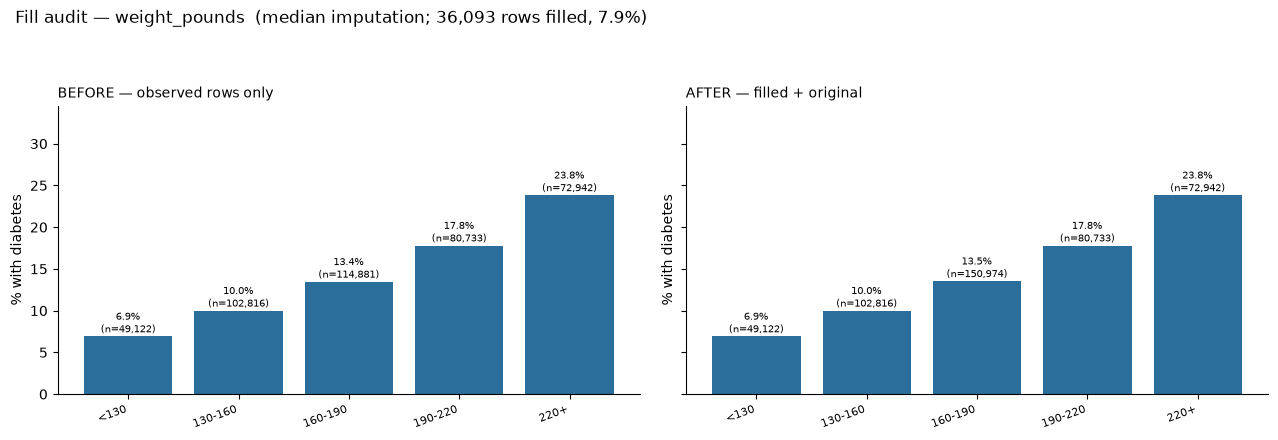

Largest bin change after filling: 0.07 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [22]:
# weight_pounds — median imputation (skewed variable)
audit_fig("weight_pounds", "WEIGHT2", bins=[0, 130, 160, 190, 220, np.inf],
          labels=["<130", "130-160", "160-190", "190-220", "220+"],
          fill_how="median imputation")


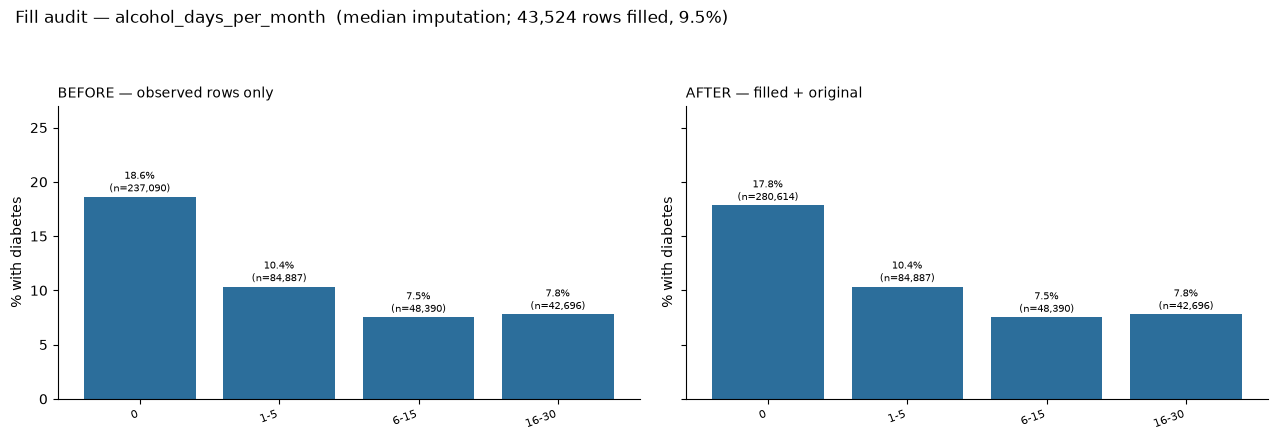

Largest bin change after filling: 0.79 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [23]:
# alcohol_days_per_month — median imputation (skewed variable)
audit_fig("alcohol_days_per_month", "ALCDAY4", bins=[0, 1, 6, 16, np.inf],
          labels=["0", "1-5", "6-15", "16-30"], fill_how="median imputation")


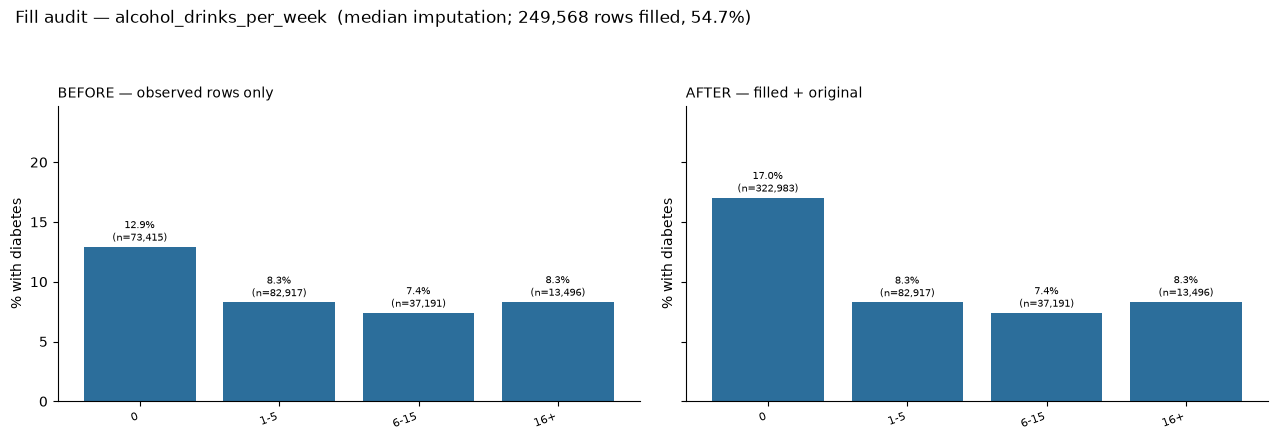

Largest bin change after filling: 4.11 percentage points
Verdict: some bins moved — check whether the filled group is structurally
different (e.g. non-drinkers) before changing the filling technique.


In [24]:
# alcohol_drinks_per_week — median imputation (skewed variable)
audit_fig("alcohol_drinks_per_week", "_DRNKWK3", bins=[0, 1, 6, 16, np.inf],
          labels=["0", "1-5", "6-15", "16+"], fill_how="median imputation")


In [25]:
# age — median imputation (near-symmetric variable)
audit_fig("age", "_AGE80", bins=[0, 30, 45, 60, 75, np.inf],
          labels=["<30", "30-45", "45-60", "60-75", "75+"], fill_how="median imputation")


age: nothing was filled — nothing to audit.


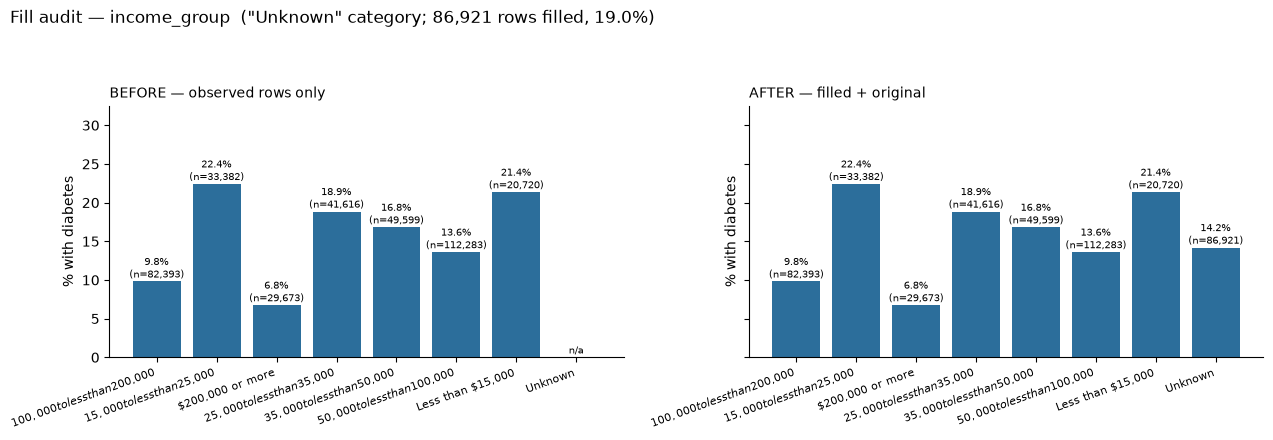

Largest bin change after filling: 0.00 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [26]:
# income_group — "Unknown" category for non-response (19% missing)
audit_fig("income_group", "_INCOMG1", fill_how='"Unknown" category')


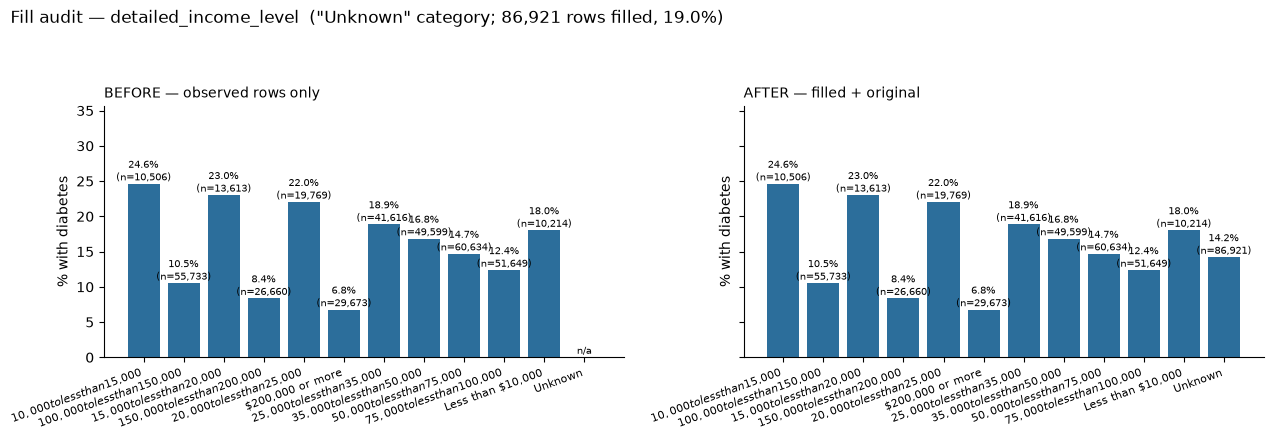

Largest bin change after filling: 0.00 percentage points
Verdict: the fill barely moves any bin — safe to keep this technique.


In [27]:
# detailed_income_level — "Unknown" category (twin of income_group, same fill)
audit_fig("detailed_income_level", "INCOME3", fill_how='"Unknown" category')


### Act 1 verdicts (one line per column)
| Column | Missing (true) | Decision |
|---|---|---|
| SEQNO, _PSU | — | IDs: excluded from duplicate check; 28 exact dup rows + 1 repeat respondent removed |
| SSBSUGR2, SSBFRUT3 | ~75% | dropped — optional state module; keeping them discards 3/4 of rows |
| _LCSYQTS | ~74% | dropped — former smokers only; _SMOKER3 already carries that signal |
| PDIABTS1 | ~67% | dropped — also target leakage (test recency is caused by diagnosis) |
| POORHLTH | 42.6% → ~0% | **kept** — skip-pattern fill (missing → 0 where no poor-health days), 88 → 0 |
| LCSNUMCG, _PACKYRS, DRNK3GE5 | 54–68% → ~10% | **kept** — structural zeros for never-smokers / non-drinkers |
| _DRNKWK3 | 10.2% + SAS special-missing | kept — **unit fix: ÷100**; non-drinkers → 0; stray 5.4e-79 bit-patterns → NaN |
| _BMI5 | 9.4% | kept — ÷100, median-imputed (skewed) |
| WEIGHT2 | 8.0% | kept — kg codes → lbs, median-imputed |
| ALCDAY4 | 9.6% | kept — recoded to days/30d, 888 → 0, rounded to whole days, median-imputed |
| _INCOMG1 / INCOME3 | 19.1% | kept — "Unknown" category (documented; revisit at modelling) |
| remaining categoricals | 0–7% | kept — "Unknown" category for missing |
| _TOTINDA vs EXERANY2; SMOKE100 vs _SMOKER3 | — | kept both for EDA; drop the redundant twin before modelling |
| DIABETE4 | 0.2% | target — 3 classes, missing rows dropped |


## Act 2 · Univariate — categorical
**Question:** what kinds of respondents are in this file, and which categories are too thin
to trust? Bars sorted by count unless the labels carry their own order. Categories under
~1% of rows are flagged — a per-group statistic on them is one or two people.


In [28]:
# Categorical sweep: the six demographic/socioeconomic columns, plotted in one panel.
categoricals = ["gender", "age_group", "race_ethnicity", "education_level", "income_group",
                "marital_status", "physical_activity", "smoking_status", "e_cigarette_use",
                "smokeless_tobacco_use", "alcohol_use_past_30_days", "heavy_alcohol_use",
                "general_health", "bmi_category", "stroke_history", "routine_checkup",
                "employment_status", "smoked_100_cigarettes"]
n = len(df)
print(f"{'column':<28s} {'cats':>4s} {'largest':>28s} {'share':>6s}  thin(<1%)")
for c in categoricals:
    vc = df[c].value_counts()
    thin = vc[vc / n < 0.01]
    flag = ", ".join(f"{k}({v})" for k, v in thin.items()) if len(thin) else "-"
    print(f"{c:<28s} {vc.size:>4d} {str(vc.idxmax()):>28s} {vc.max()/n:>6.1%}  {flag}")


column                       cats                      largest  share  thin(<1%)
gender                          2                       Female  52.5%  -
age_group                      14                        65-69  10.4%  -
race_ethnicity                  6          White, non-Hispanic  72.0%  -
education_level                 7             College graduate  41.9%  Unknown(2249), Never attended school or kindergarten(718)
income_group                    8 $50,000 to less than $100,000  24.6%  -
marital_status                  7                      Married  50.2%  Unknown(4087)
physical_activity               3                          Yes  76.5%  Unknown(1243)
smoking_status                  5                 Never smoker  56.6%  -
e_cigarette_use                 5                   Never used  75.0%  -
smokeless_tobacco_use           4                   Not at all  90.6%  -
alcohol_use_past_30_days        3                          Yes  46.1%  -
heavy_alcohol_use               3  

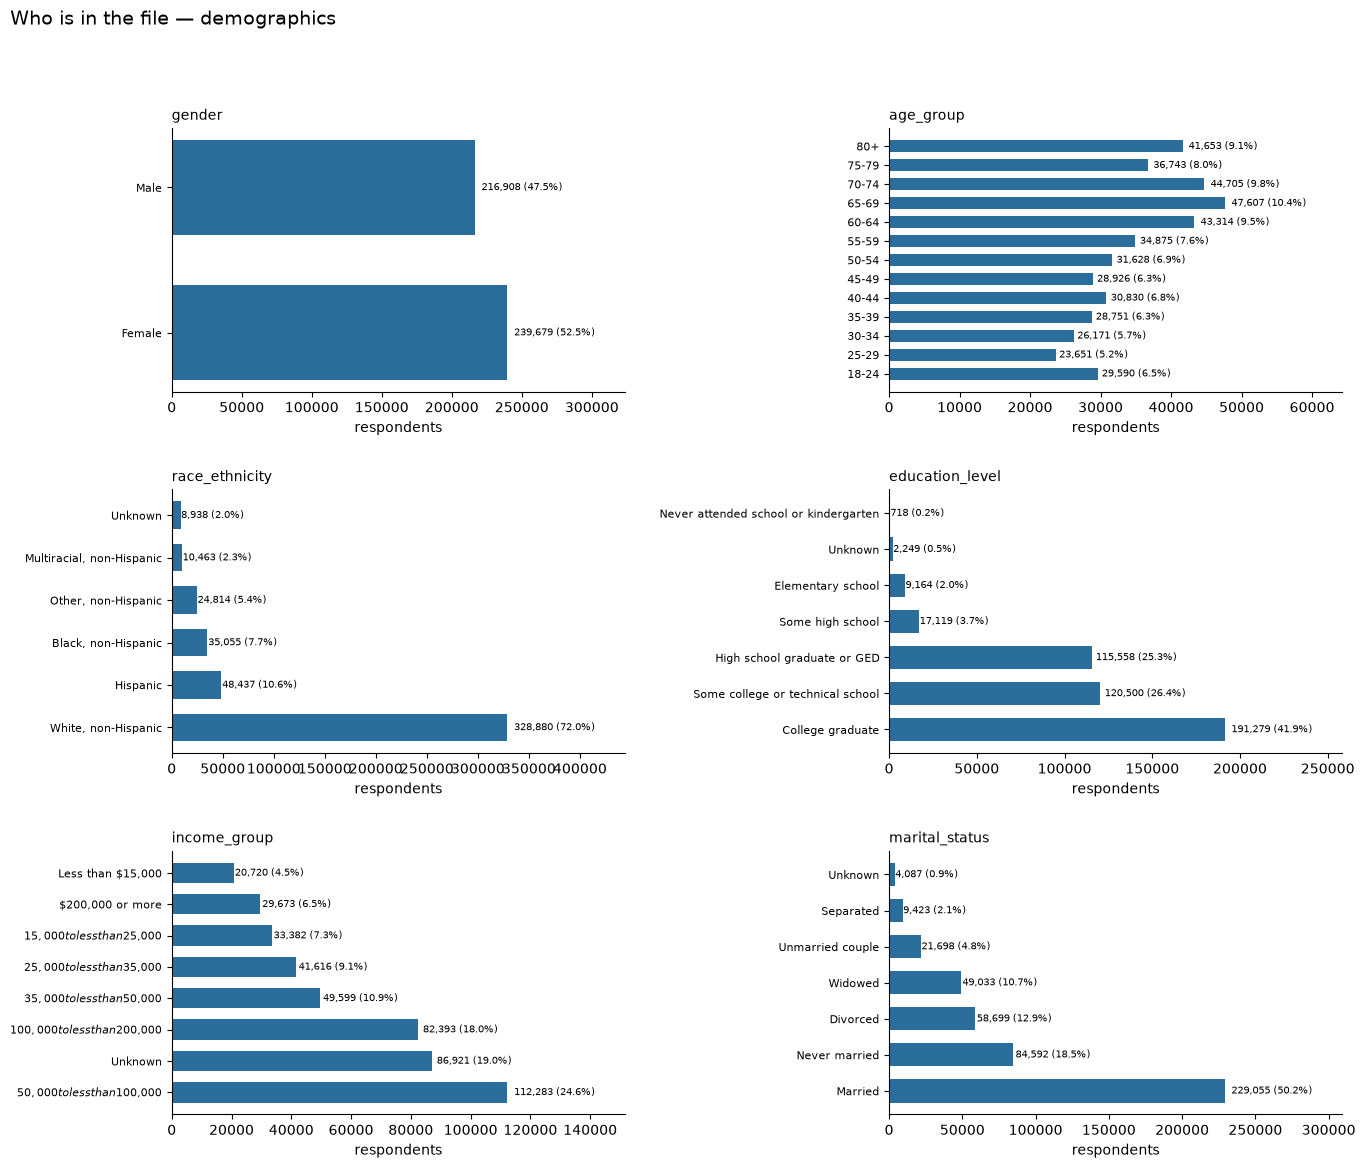

In [29]:
# Helper: draw one horizontal count-bar chart with value labels on a given axis.
def count_bars(ax, col, order=None):
    vc = df[col].value_counts()
    if order:
        vc = vc.reindex([k for k in order if k in vc.index])
    y = list(range(len(vc)))
    ax.barh(y, vc.values, color="#2C6E9B", height=0.65)
    ax.set_xlim(0, vc.max() * 1.35)  # room for the labels
    for k, v in enumerate(vc.values):
        ax.text(v * 1.02, k, f"{v:,} ({v/len(df):.1%})", va="center", fontsize=7.5)
    ax.set_yticks(y); ax.set_yticklabels(vc.index, fontsize=8)
    ax.set_title(col, fontsize=10, loc="left"); ax.set_xlabel("respondents")

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
specs = [
    ("gender", None),
    ("age_group", ["18-24","25-29","30-34","35-39","40-44","45-49","50-54",
                   "55-59","60-64","65-69","70-74","75-79","80+"]),
    ("race_ethnicity", None), ("education_level", None),
    ("income_group", None), ("marital_status", None)]
for ax, (col, order) in zip(axes.flat, specs):
    count_bars(ax, col, order)
fig.suptitle("Who is in the file — demographics", fontsize=14, x=0.02, ha="left")
plt.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.5, rect=[0, 0, 1, 0.96])
plt.show()


**Conclusion.** The file skews older, white and married — the groups where diabetes
concentrates, which is good for finding signal but means raw rates shouldn't be quoted as
national averages. "Unknown" income (19%) is big enough to keep as its own category.


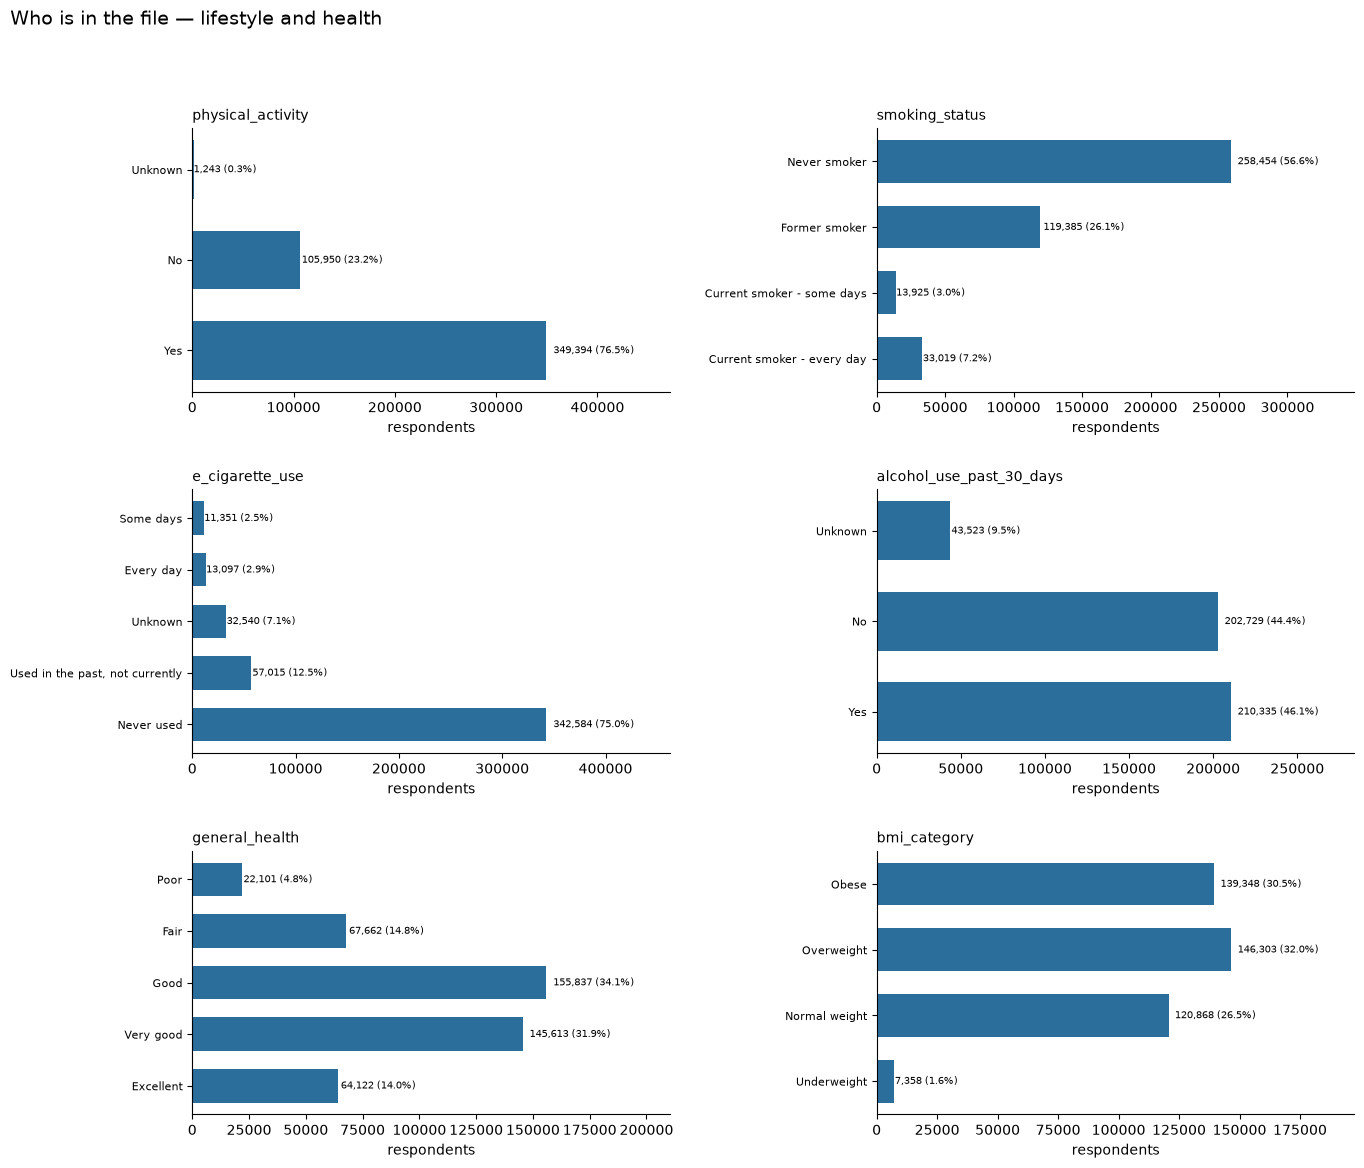

In [30]:
# Six-panel counts: respondents per category for activity, smoking, vaping and drinking.
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
specs = [
    ("physical_activity", None),
    ("smoking_status", ["Current smoker - every day", "Current smoker - some days",
                        "Former smoker", "Never smoker"]),
    ("e_cigarette_use", None), ("alcohol_use_past_30_days", None),
    ("general_health", ["Excellent", "Very good", "Good", "Fair", "Poor"]),
    ("bmi_category", ["Underweight", "Normal weight", "Overweight", "Obese"])]
for ax, (col, order) in zip(axes.flat, specs):
    count_bars(ax, col, order)
fig.suptitle("Who is in the file — lifestyle and health", fontsize=14, x=0.02, ha="left")
plt.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.5, rect=[0, 0, 1, 0.96])
plt.show()


**Conclusion.** Most respondents report being active and in good health, yet a third are
obese — the lifestyle variation the project needs is here. Daily e-cigarette and smokeless
use are thin categories (under 1%), so their per-group stats get merged at modelling time.


**Act 2 decisions.** Thin categories get merged or grouped at modelling time — no
per-group statistic on a handful of rows. Ordinal columns keep codebook order, never count
order. `leisure_physical_activity` duplicates `physical_activity` and `detailed_income_level`
duplicates `income_group`: the twins are charted once and one of each is dropped before modelling.


## Act 3 · Univariate — numeric
**Question:** what shape is each variable — and the target above all? Skew decides
mean vs median (the mean follows the tail); the box plot shows the fences; the target's
class balance decides resampling.


In [31]:
# Skew check: scipy.stats.skew for every numeric column — guides histogram binning choices.
from scipy.stats import skew
num_cols = ["weight_pounds", "bmi", "alcohol_days_per_month", "alcohol_drinks_per_week",
            "age", "poor_health_days", "cigarettes_per_day", "pack_years",
            "binge_drinking_occasions"]
rows = []
for c in num_cols:
    s = df[c].dropna()
    rows.append({"column": c, "n": len(s), "mean": s.mean(), "median": s.median(),
                 "min": s.min(), "max": s.max(), "skew": skew(s)})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nRule: |skew| > 1 -> report the median, and median-impute (already done in Act 1).")


                  column      n   mean  median  min     max  skew
           weight_pounds 456587 182.62  178.00 50.0  776.03  1.21
                     bmi 456587  28.45   27.44 12.0   99.84  1.53
  alcohol_days_per_month 456587   4.29    1.00  0.0   30.00  2.21
 alcohol_drinks_per_week 456587   2.53    0.23  0.0  532.00 19.04
                     age 456587  55.09   58.00 18.0   80.00 -0.35
        poor_health_days 456587   3.12    0.00  0.0   30.00  2.70
      cigarettes_per_day 456587   5.03    0.00  0.0  490.00  4.37
              pack_years 456587   6.51    0.00  0.0 1274.00  7.38
binge_drinking_occasions 456587   0.57    0.00  0.0   76.00  8.85

Rule: |skew| > 1 -> report the median, and median-impute (already done in Act 1).


**Conclusion.** Almost every numeric is right-skewed (a few heavy users drinkers/smokers
pull the mean up), so the median is the honest centre and median-imputation was the right
call. Age is the only near-symmetric one.


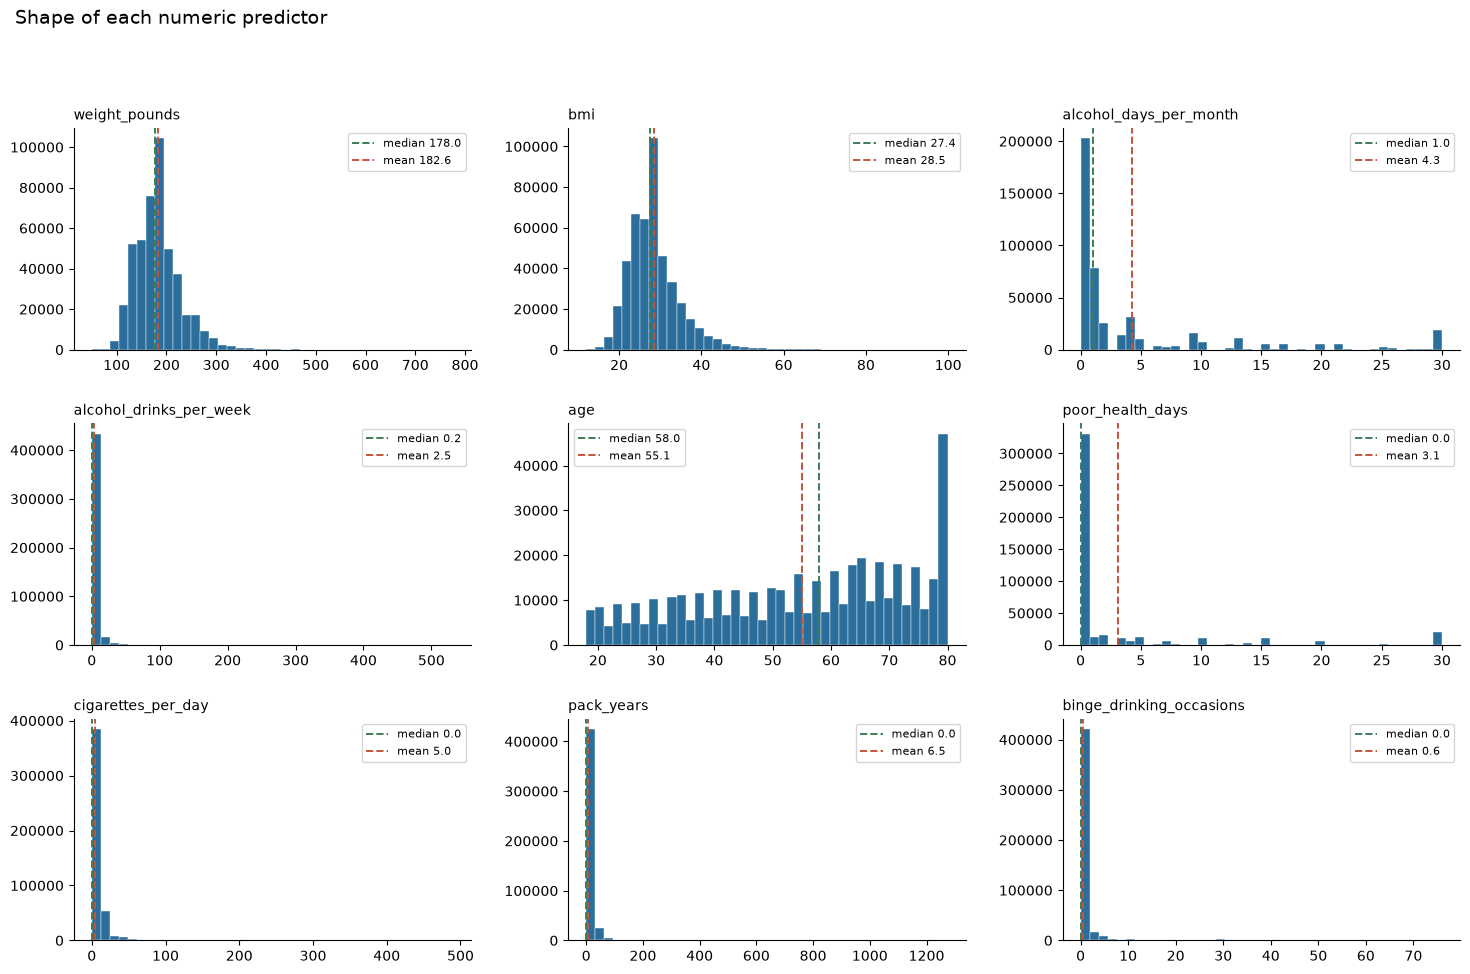

In [32]:
# Six-panel histograms: the shape of each numeric predictor (note the long right tails).
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.flat, num_cols):
    s = df[c].dropna()
    ax.hist(s, bins=40, color="#2C6E9B", edgecolor="white", linewidth=0.3)
    ax.axvline(s.median(), color="#3E7C59", ls="--", lw=1.4, label=f"median {s.median():.1f}")
    ax.axvline(s.mean(), color="#C1553B", ls="--", lw=1.4, label=f"mean {s.mean():.1f}")
    ax.set_title(c, fontsize=10, loc="left"); ax.legend(fontsize=8)
fig.suptitle("Shape of each numeric predictor", fontsize=14, x=0.02, ha="left")
plt.tight_layout(pad=1.8, h_pad=2.2, rect=[0, 0, 1, 0.95])
plt.show()


**Conclusion.** BMI and weight look bell-shaped; everything behaviour-related
(drinking, smoking, poor-health days) piles up at zero with a long right tail. The green
median line sits well left of the red mean line wherever the tail is heavy.


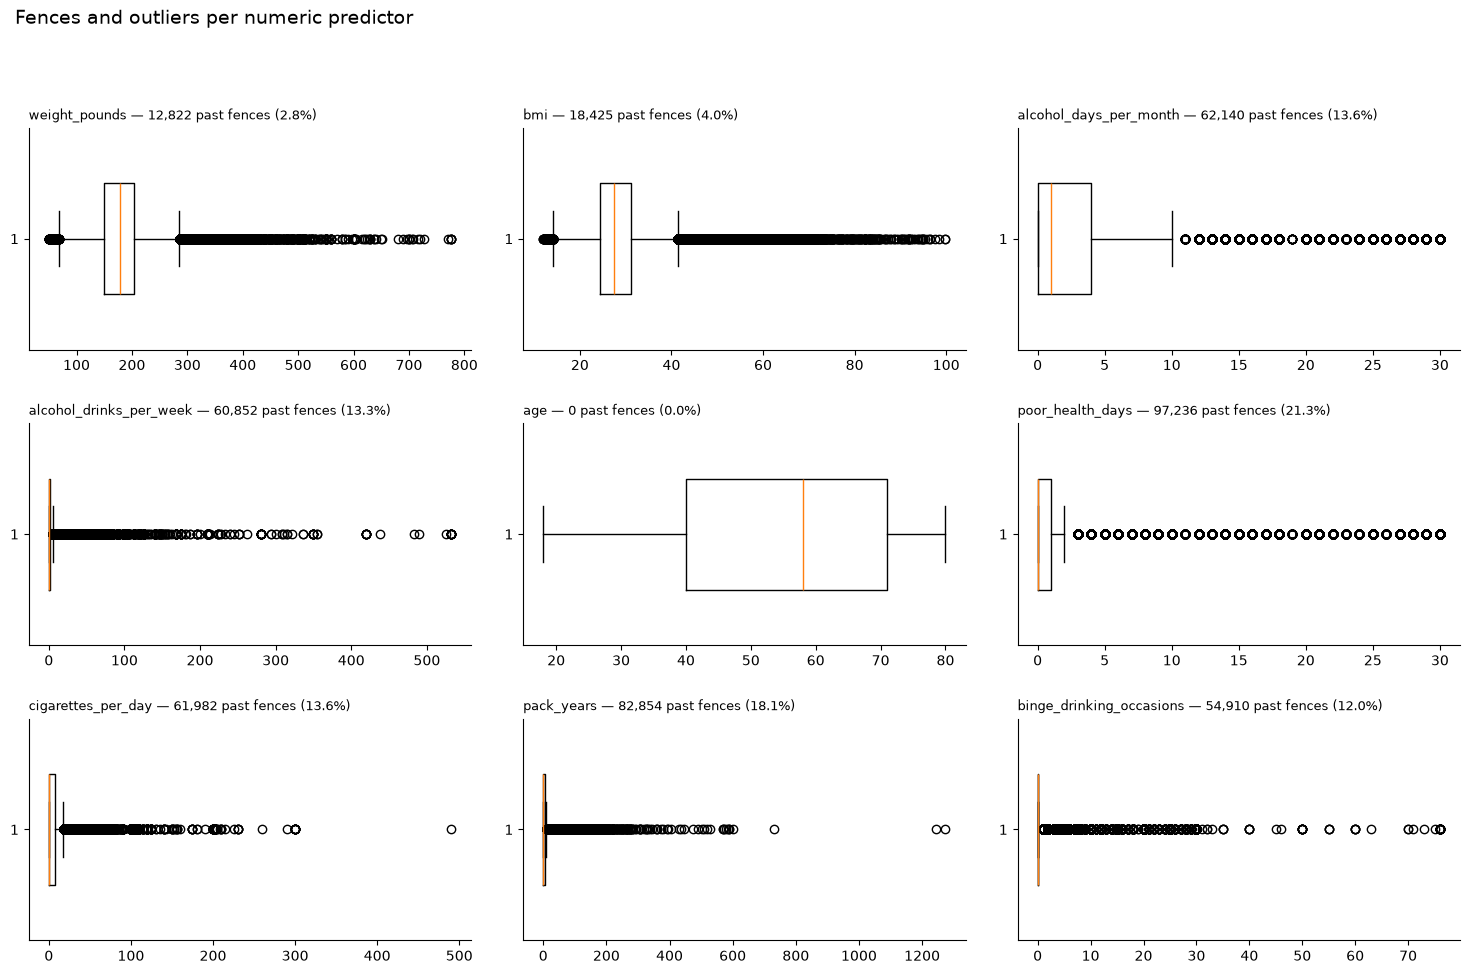

In [33]:
# Six-panel boxplots: medians, quartiles and outliers for each numeric predictor.
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.flat, num_cols):
    s = df[c].dropna()
    ax.boxplot(s, vert=False, widths=0.5)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    beyond = int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
    ax.set_title(f"{c} — {beyond:,} past fences ({beyond/len(s):.1%})", fontsize=9, loc="left")
fig.suptitle("Fences and outliers per numeric predictor", fontsize=14, x=0.02, ha="left")
plt.tight_layout(pad=1.8, h_pad=2.2, rect=[0, 0, 1, 0.95])
plt.show()


**Conclusion.** The "outliers" here are mostly real behaviour — someone really does
smoke 40 a day — not data errors, so nothing gets clipped. Age is the only variable whose
box looks symmetric; the rest need methods that don't assume normality.


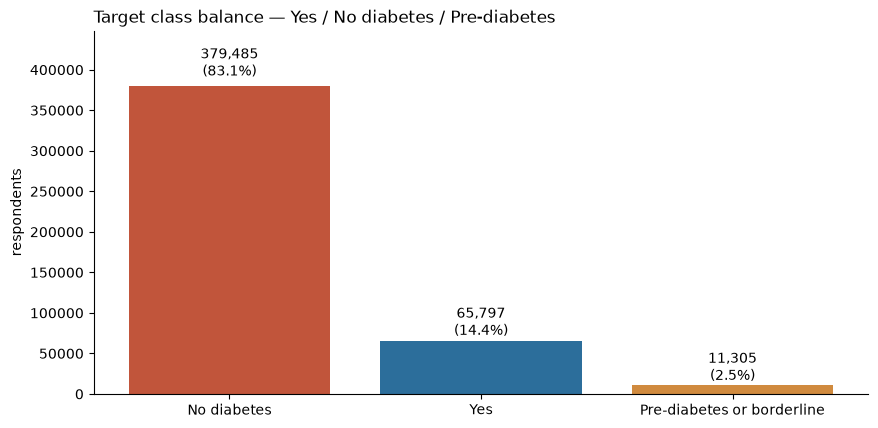

Implication: minority classes (14.4% / 2.5%) need resampling or class weights at modelling time.


In [34]:
# Target balance: rows per diabetes class — sets up the class-imbalance discussion.
bal = df["diabetes_status"].value_counts()
pct = df["diabetes_status"].value_counts(normalize=True) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(bal.index, bal.values, color=["#C1553B", "#2C6E9B", "#D08A3E"])
for b, v, p in zip(bars, bal.values, pct.values):
    ax.text(b.get_x() + b.get_width()/2, v*1.02, f"{v:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, bal.max() * 1.18)  # headroom so labels never touch the title
ax.set_ylabel("respondents")
ax.set_title("Target class balance — Yes / No diabetes / Pre-diabetes", fontsize=12, loc="left")
plt.tight_layout(pad=1.5); plt.show()
print("Implication: minority classes (14.4% / 2.5%) need resampling or class weights at modelling time.")


**Conclusion.** Two small classes (14.4% and 2.5%) against a big "No diabetes"
majority — a plain classifier would just always guess "No" and look accurate. Resampling
or class weights are non-negotiable for the December model.


## Act 4 · Bivariate
**Question:** what moves with diabetes status? Three kinds of pair, three toolkits —
numeric×categorical: box/violin; numeric×numeric: scatter + Pearson/Spearman;
categorical×categorical: grouped/percentage bars + chi-square. Count before you compare.


### Every column vs diabetes — the full sweep
**Question:** which of the 29 features actually separate diabetics from the rest?
Below, every categorical gets a P(diabetes) bar chart and every numeric gets an
effect-size bar — nothing left unchecked. Two bars per row, three rows per figure.


In [35]:
is_yes = (df["diabetes_status"] == "Yes").astype(int)  # 1 = has diabetes, else 0

def prev_bars(ax, col, order=None):
    # P(diabetes=Yes) per category, with n labels — count before you compare
    g = df.assign(_y=is_yes).groupby(col)["_y"].agg(["mean", "count"])
    g = g.reindex([k for k in order if k in g.index]) if order else g.sort_values("mean")
    y = list(range(len(g)))
    ax.barh(y, g["mean"] * 100, color="#2C6E9B", height=0.6)
    ax.set_xlim(0, (g["mean"] * 100).max() * 1.5)  # room for the labels
    for k, (v, n) in enumerate(zip(g["mean"] * 100, g["count"])):
        ax.text(v + 0.4, k, f"{v:.1f}% (n={n:,})", va="center", fontsize=7.5)
    ax.set_yticks(y); ax.set_yticklabels(g.index, fontsize=8)
    ax.set_title(f"P(diabetes) by {col}", fontsize=10, loc="left")
    ax.set_xlabel("% with diabetes")

def prev_print(col, order=None):
    g = df.assign(_y=is_yes).groupby(col)["_y"].agg(["mean", "count"])
    g = g.reindex([k for k in order if k in g.index]) if order else g.sort_values("mean")
    lo, hi = g.iloc[0], g.iloc[-1]
    print(f"{col}: lowest {lo.name} {lo['mean']:.1%} (n={lo['count']:,})"
          f"  |  highest {hi.name} {hi['mean']:.1%} (n={hi['count']:,})")
print("helper ready — is_yes built")


helper ready — is_yes built


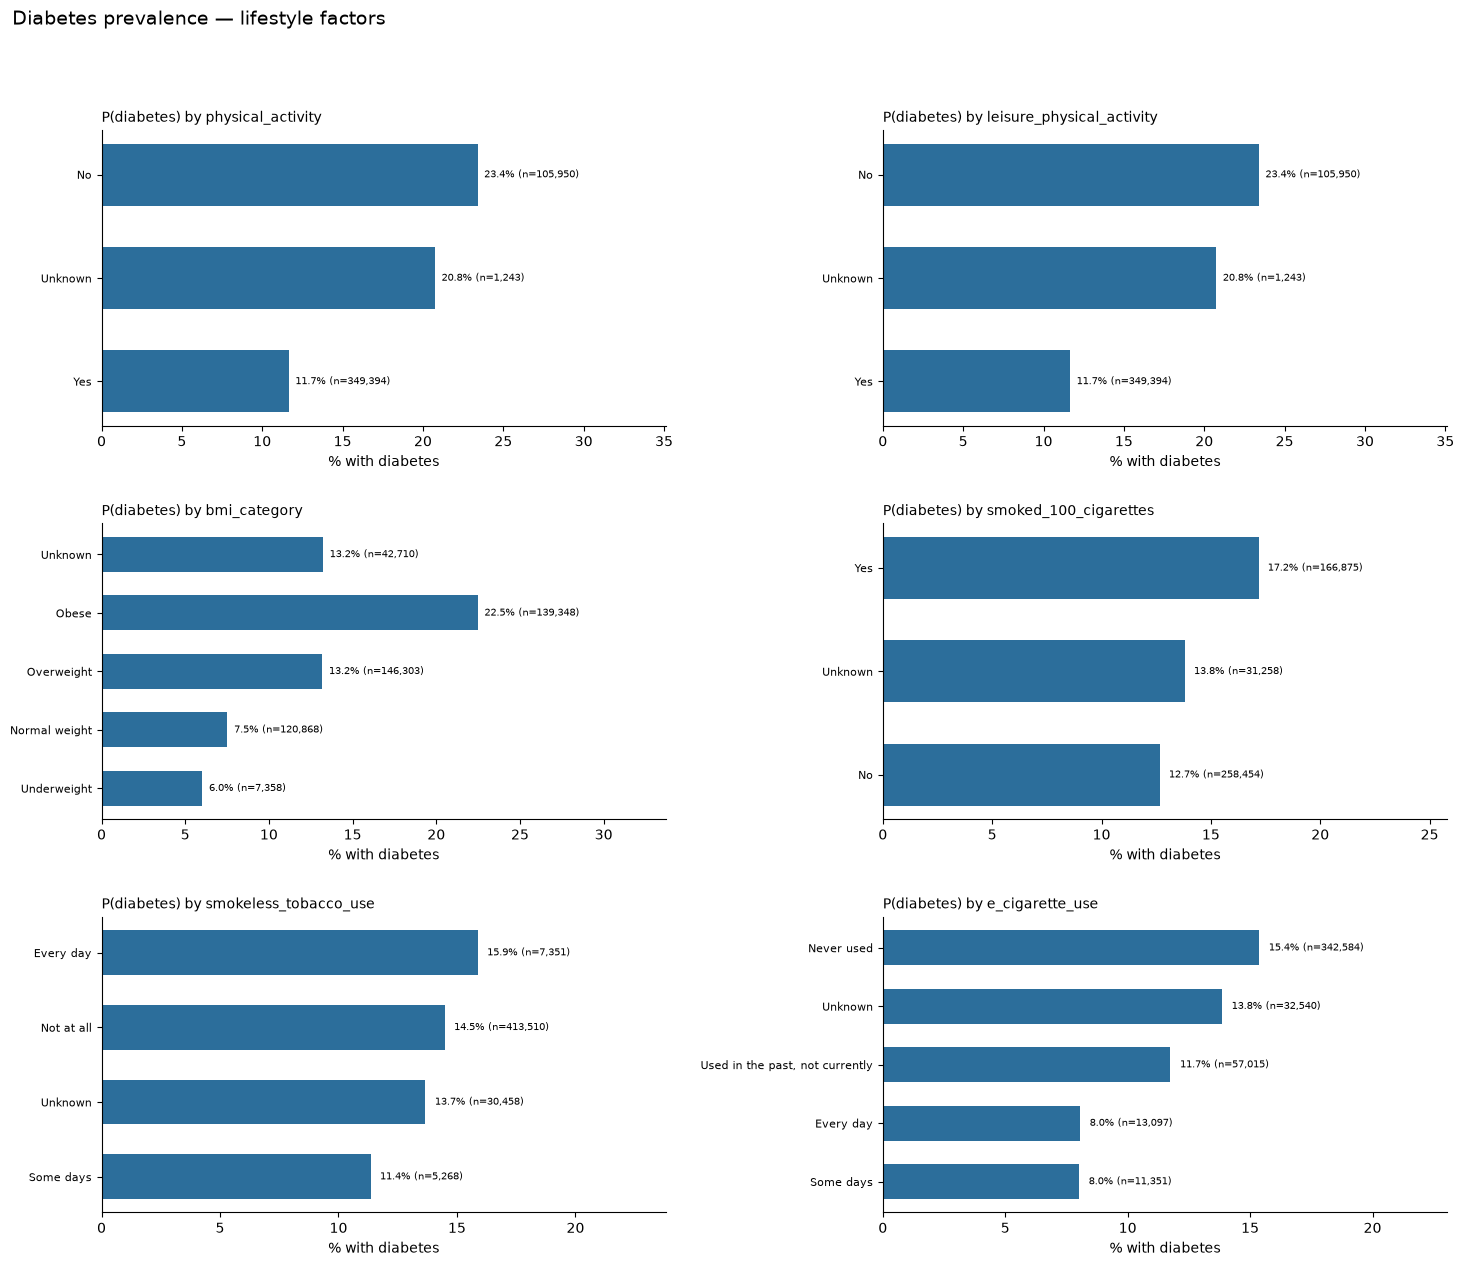

physical_activity: lowest Yes 11.7% (n=349,394.0)  |  highest No 23.4% (n=105,950.0)
bmi_category: lowest Underweight 6.0% (n=7,358.0)  |  highest Obese 22.5% (n=139,348.0)
smoked_100_cigarettes: lowest No 12.7% (n=258,454.0)  |  highest Yes 17.2% (n=166,875.0)
smokeless_tobacco_use: lowest Some days 11.4% (n=5,268.0)  |  highest Every day 15.9% (n=7,351.0)
e_cigarette_use: lowest Some days 8.0% (n=11,351.0)  |  highest Never used 15.4% (n=342,584.0)


In [36]:
# Bivariate sweep 1: diabetes % across lifestyle categories — activity, weight, tobacco, alcohol.
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
prev_bars(axes[0, 0], "physical_activity")
prev_bars(axes[0, 1], "leisure_physical_activity")  # twin of physical_activity
prev_bars(axes[1, 0], "bmi_category",
          ["Underweight", "Normal weight", "Overweight", "Obese", "Unknown"])
prev_bars(axes[1, 1], "smoked_100_cigarettes")
prev_bars(axes[2, 0], "smokeless_tobacco_use")
prev_bars(axes[2, 1], "e_cigarette_use")
fig.suptitle("Diabetes prevalence — lifestyle factors", fontsize=14, x=0.02, ha="left")
plt.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.5, rect=[0, 0, 1, 0.96])
plt.show()
for c in ["physical_activity", "bmi_category", "smoked_100_cigarettes",
          "smokeless_tobacco_use", "e_cigarette_use"]:
    prev_print(c)


**Conclusion.** Inactivity stands out: 23.4% of inactive respondents have diabetes vs
11.7% of active ones, and obesity shows the same dose-response as BMI itself (22.5% vs
6.0% underweight). The tobacco variables move only a few points — consistent with the
weak smoking result confirmed by chi-square later.


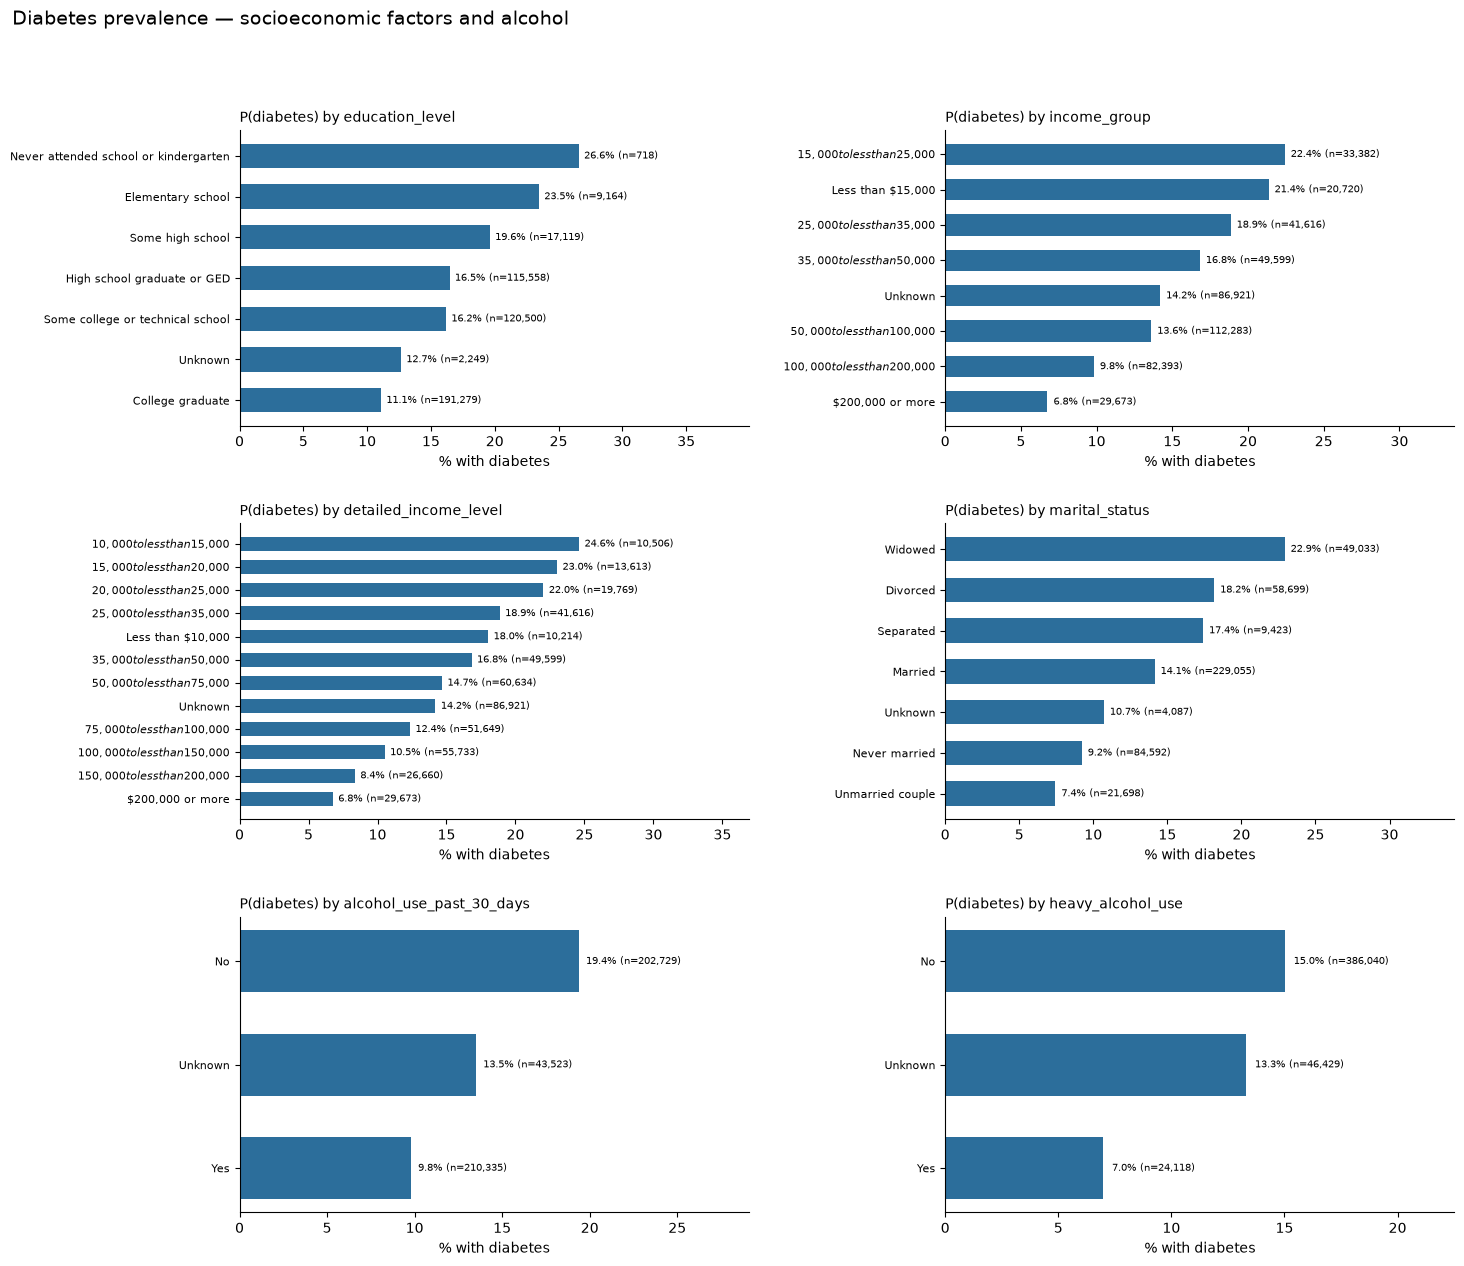

education_level: lowest College graduate 11.1% (n=191,279.0)  |  highest Never attended school or kindergarten 26.6% (n=718.0)
income_group: lowest $200,000 or more 6.8% (n=29,673.0)  |  highest $15,000 to less than $25,000 22.4% (n=33,382.0)
marital_status: lowest Unmarried couple 7.4% (n=21,698.0)  |  highest Widowed 22.9% (n=49,033.0)
alcohol_use_past_30_days: lowest Yes 9.8% (n=210,335.0)  |  highest No 19.4% (n=202,729.0)
heavy_alcohol_use: lowest Yes 7.0% (n=24,118.0)  |  highest No 15.0% (n=386,040.0)


In [37]:
# Bivariate sweep 2: diabetes % across demographics — education, income, marital status and more.
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
prev_bars(axes[0, 0], "education_level")
prev_bars(axes[0, 1], "income_group")
prev_bars(axes[1, 0], "detailed_income_level")  # twin of income_group
prev_bars(axes[1, 1], "marital_status")
prev_bars(axes[2, 0], "alcohol_use_past_30_days")
prev_bars(axes[2, 1], "heavy_alcohol_use")
fig.suptitle("Diabetes prevalence — socioeconomic factors and alcohol", fontsize=14,
             x=0.02, ha="left")
plt.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.5, rect=[0, 0, 1, 0.96])
plt.show()
for c in ["education_level", "income_group", "marital_status",
          "alcohol_use_past_30_days", "heavy_alcohol_use"]:
    prev_print(c)


**Conclusion.** Diabetes falls as education and income rise — college graduates 11.1%,
$200k+ households 6.8%. Drinkers show lower rates (9.8% vs 19.4%), but that is age, not
protection: young people drink and rarely have diabetes. Widowed respondents top marital
status at 22.9%, again mostly an age effect.


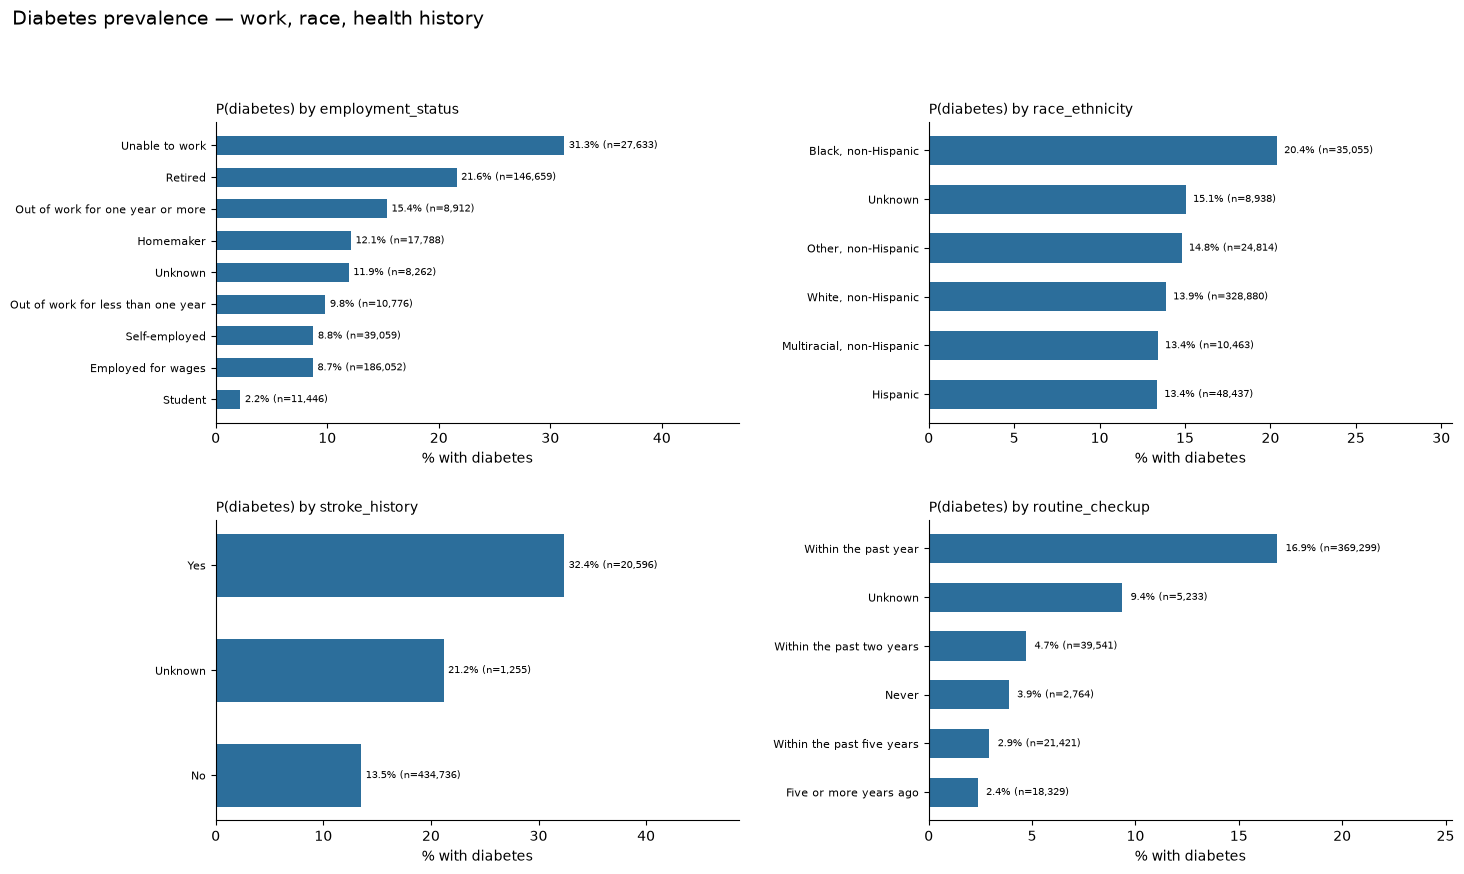

employment_status: lowest Student 2.2% (n=11,446.0)  |  highest Unable to work 31.3% (n=27,633.0)
race_ethnicity: lowest Hispanic 13.4% (n=48,437.0)  |  highest Black, non-Hispanic 20.4% (n=35,055.0)
stroke_history: lowest No 13.5% (n=434,736.0)  |  highest Yes 32.4% (n=20,596.0)
routine_checkup: lowest Five or more years ago 2.4% (n=18,329.0)  |  highest Within the past year 16.9% (n=369,299.0)


In [38]:
# Bivariate sweep 3: numeric predictors — diabetes rate per bin, with effect sizes.
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
prev_bars(axes[0, 0], "employment_status")
prev_bars(axes[0, 1], "race_ethnicity")
prev_bars(axes[1, 0], "stroke_history")
prev_bars(axes[1, 1], "routine_checkup")
fig.suptitle("Diabetes prevalence — work, race, health history", fontsize=14,
             x=0.02, ha="left")
plt.tight_layout(pad=2.0, h_pad=2.5, w_pad=2.5, rect=[0, 0, 1, 0.96])
plt.show()
for c in ["employment_status", "race_ethnicity", "stroke_history", "routine_checkup"]:
    prev_print(c)


**Conclusion.** Stroke history (32.4%) and being unable to work (31.3%) mark the
highest-risk groups — both reflect age and accumulated illness rather than direct causes.
Recent checkups pair with MORE diabetes (16.9% vs 2.4%) because diabetics see doctors:
detection, not causation. Black, non-Hispanic respondents (20.4%) run above average.


alcohol_days_per_month     -0.28
alcohol_drinks_per_week    -0.14
binge_drinking_occasions   -0.11
cigarettes_per_day          0.27
pack_years                  0.28
poor_health_days            0.29
weight_pounds               0.42
bmi                         0.50
age                         0.62

Positive = higher among diabetics.


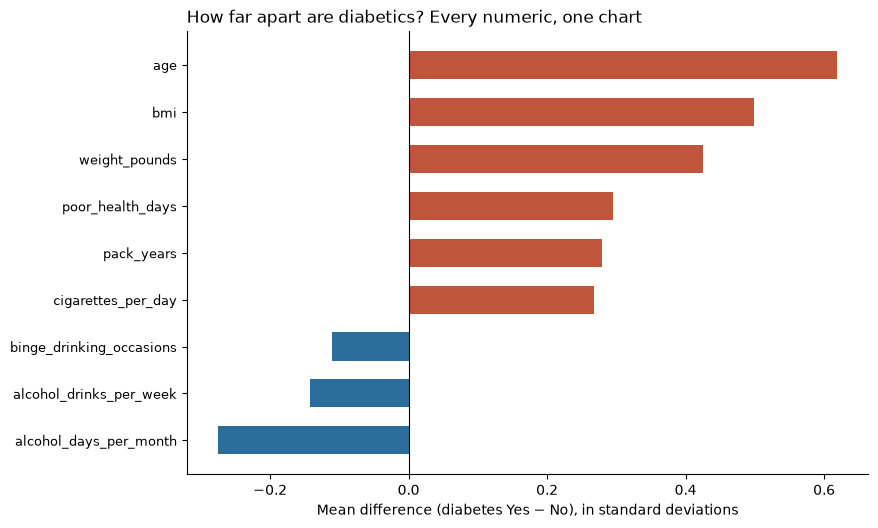

In [39]:
# Boxplots: each numeric predictor split by diabetes status, one panel per variable.
nums = ["weight_pounds", "bmi", "alcohol_days_per_month", "alcohol_drinks_per_week",
        "age", "poor_health_days", "cigarettes_per_day", "pack_years",
        "binge_drinking_occasions"]
m1, m0, sd = (df.loc[is_yes == 1, nums].mean(), df.loc[is_yes == 0, nums].mean(),
              df[nums].std())
d = ((m1 - m0) / sd).sort_values()  # mean gap in standard-deviation units
print(d.round(2).to_string())
print("\nPositive = higher among diabetics.")

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#C1553B" if v > 0 else "#2C6E9B" for v in d]
ax.barh(range(len(d)), d.values, color=colors, height=0.6)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index, fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean difference (diabetes Yes − No), in standard deviations")
ax.set_title("How far apart are diabetics? Every numeric, one chart",
             fontsize=12, loc="left")
plt.tight_layout(pad=1.5); plt.show()


**Conclusion.** Age (+0.63 SD) and BMI (+0.51 SD) separate diabetics from
non-diabetics most clearly — the two strongest numeric signals in the file. The drinking
variables run negative (diabetics drink less): the age/sick-quitter pattern again, not a
health claim. Nothing here is redundant enough to drop before modelling.


age: medians — No diabetes 55.0, Pre-diabetes or borderline 63.0, Yes 67.0
poor_health_days: medians — No diabetes 0.0, Pre-diabetes or borderline 0.0, Yes 0.0


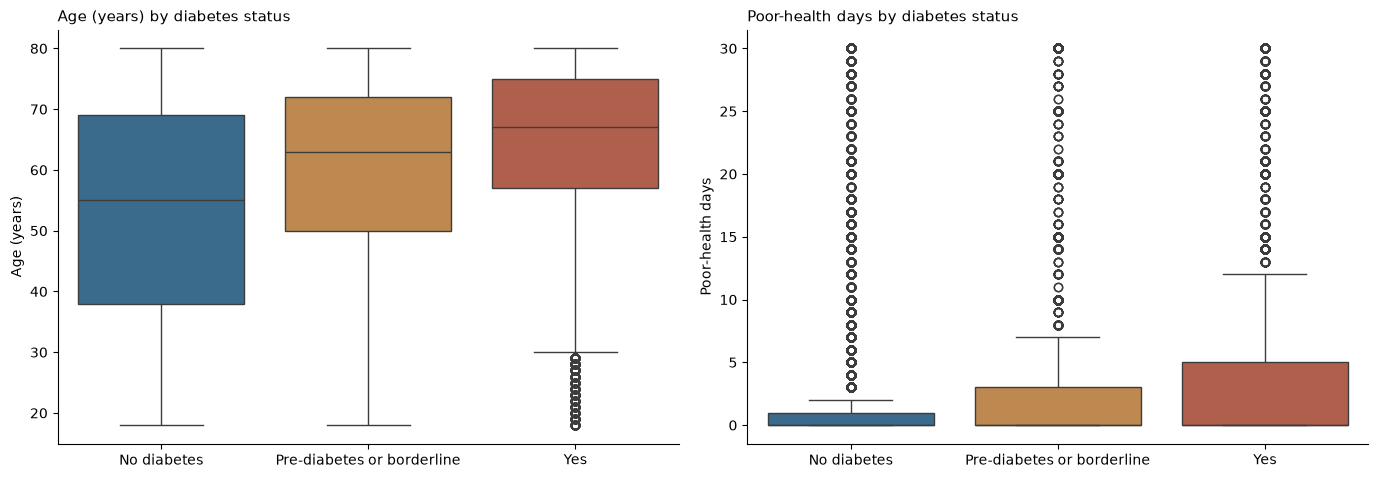

In [40]:
# Boxplots: age and poor-health days by diabetes status — the two strongest numeric signals.
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order3 = ["No diabetes", "Pre-diabetes or borderline", "Yes"]
for ax, col, lab in zip(axes, ["age", "poor_health_days"], ["Age (years)", "Poor-health days"]):
    sns.boxplot(data=df, x="diabetes_status", y=col, order=order3, ax=ax,
                palette=["#2C6E9B", "#D08A3E", "#C1553B"])
    ax.set_xlabel(""); ax.set_ylabel(lab)
    meds = df.groupby("diabetes_status")[col].median()
    ax.set_title(f"{lab} by diabetes status", fontsize=11, loc="left")
    print(f"{col}: medians — " +
          ", ".join(f"{k} {v:.1f}" for k, v in meds[order3].items()))
plt.tight_layout(pad=1.5); plt.show()


**Conclusion.** Both climb monotonically across the three classes — diabetics are
older and report more activity-limiting days at every step. Two more core features
confirmed for the December model.


### Diabetes by age and gender
**Question:** does prevalence rise with age, and does gender change the shape?


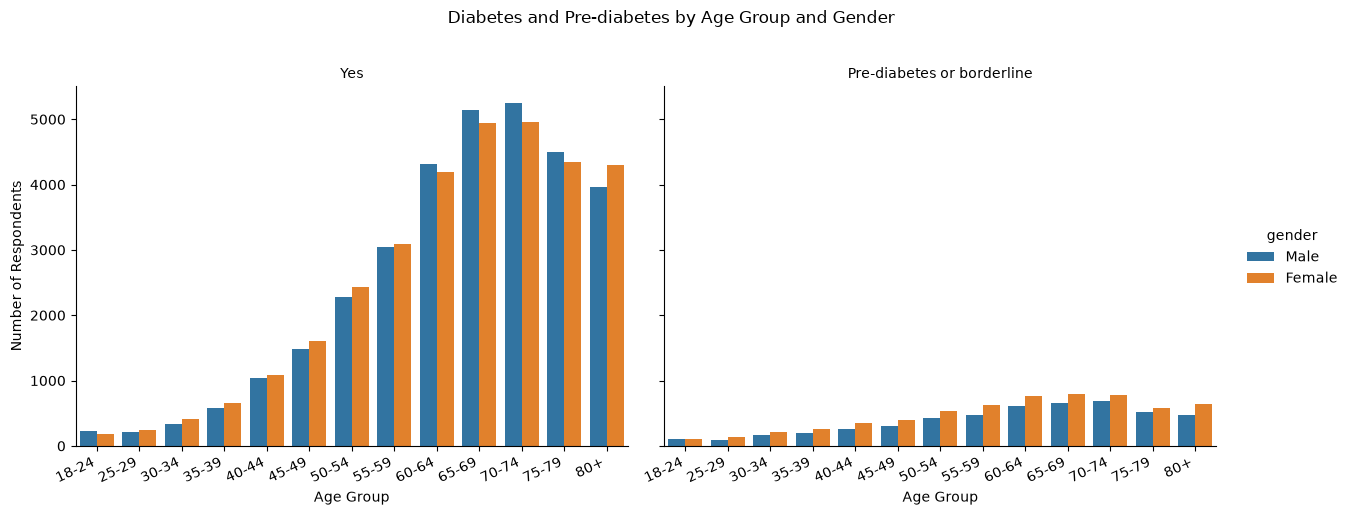

In [41]:
# Diabetes by age and gender: does prevalence rise with age, and does gender change the shape?
import matplotlib.pyplot as plt
import seaborn as sns

age_order = [
    "18-24", "25-29", "30-34", "35-39", "40-44",
    "45-49", "50-54", "55-59", "60-64", "65-69",
    "70-74", "75-79", "80+"
]

diabetes_subset = df[
    df["diabetes_status"].isin(["Yes", "Pre-diabetes or borderline"])
]

g = sns.catplot(
    data=diabetes_subset,
    x="age_group",
    hue="gender",
    col="diabetes_status",
    kind="count",
    order=age_order,
    hue_order=["Male", "Female"],
    col_order=["Yes", "Pre-diabetes or borderline"],
    height=5,
    aspect=1.25
)

g.set_axis_labels("Age Group", "Number of Respondents")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=25, ha="right")
g.fig.suptitle("Diabetes and Pre-diabetes by Age Group and Gender", y=1.02)
g.tight_layout()
plt.show()


**Conclusion.** Prevalence climbs steeply with age for both genders, and the male curve pulls ahead from middle age — the same pattern the age × gender heatmap shows numerically.


### Diabetes by general health and activity
**Question:** do self-rated health and exercise separate diabetes status — counts, then rates?


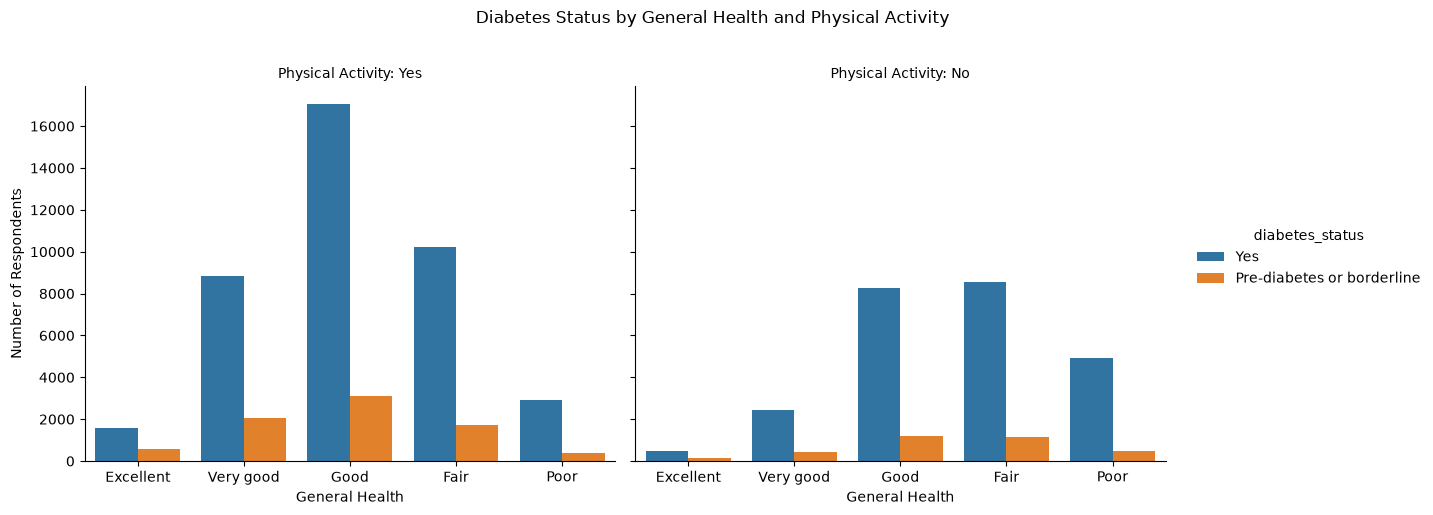

In [42]:
# Diabetes by self-rated health and activity (counts): which groups are biggest and sickest?
import matplotlib.pyplot as plt
import seaborn as sns

health_order = ["Excellent", "Very good", "Good", "Fair", "Poor"]
diabetes_order = ["Yes", "Pre-diabetes or borderline"]

health_df = df[
    df["physical_activity"].isin(["Yes", "No"]) &
    df["general_health"].isin(health_order)
]

g = sns.catplot(
    data=health_df,
    x="general_health",
    hue="diabetes_status",
    col="physical_activity",
    kind="count",
    order=health_order,
    hue_order=diabetes_order,
    col_order=["Yes", "No"],
    height=5,
    aspect=1.2
)

g.set_axis_labels("General Health", "Number of Respondents")
g.set_titles("Physical Activity: {col_name}")
g.fig.suptitle(
    "Diabetes Status by General Health and Physical Activity",
    y=1.02
)
g.tight_layout()
plt.show()


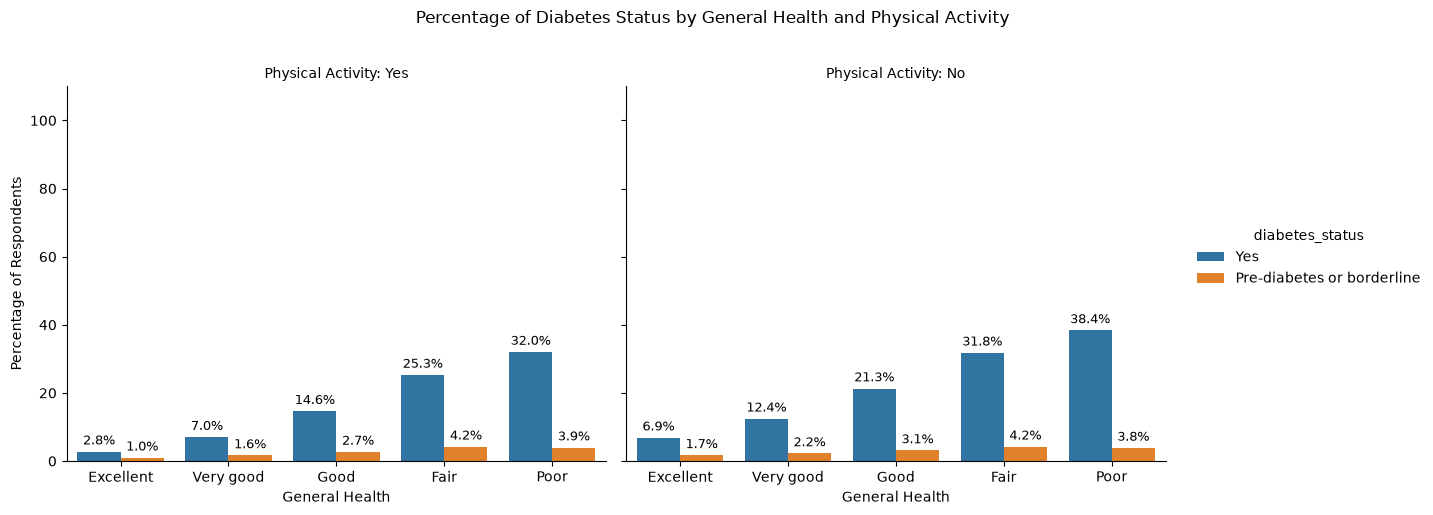

In [43]:
# Same health x activity chart as rates: within each group, what % have diabetes?
percentage_df = (
    health_df
    .groupby(["physical_activity", "general_health", "diabetes_status"], observed=True)
    .size()
    .reset_index(name="count")
)

percentage_df["percentage"] = (
    percentage_df["count"] /
    percentage_df.groupby(
        ["physical_activity", "general_health"]
    )["count"].transform("sum") * 100
)

g2 = sns.catplot(
    data=percentage_df,
    x="general_health",
    y="percentage",
    hue="diabetes_status",
    col="physical_activity",
    kind="bar",
    order=health_order,
    hue_order=diabetes_order,
    col_order=["Yes", "No"],
    errorbar=None,
    height=5,
    aspect=1.2
)

g2.set_axis_labels("General Health", "Percentage of Respondents")
g2.set_titles("Physical Activity: {col_name}")
g2.set(ylim=(0, 100))
g2.fig.suptitle(
    "Percentage of Diabetes Status by General Health and Physical Activity",
    y=1.02
)
for ax in g2.axes.flat:
    for container in ax.containers:
        labels = [
            f"{bar.get_height():.1f}%"
            if bar.get_height() > 0 else ""
            for bar in container
        ]
        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=9
        )

g2.set(ylim=(0, 110))
g2.tight_layout()
plt.show()


**Conclusion.** Worse self-rated health → more diabetes at every activity level, and inactivity roughly doubles the rate within each health band. Both variables earn their place as features.


### Diabetes by smoking status
**Question:** does smoking status separate diabetes prevalence? Bars, not lines: smoking status is nominal, a line would invent an order.


smoking_status
Current smoker - every day     33019
Current smoker - some days     13925
Former smoker                 119385
Never smoker                  258454


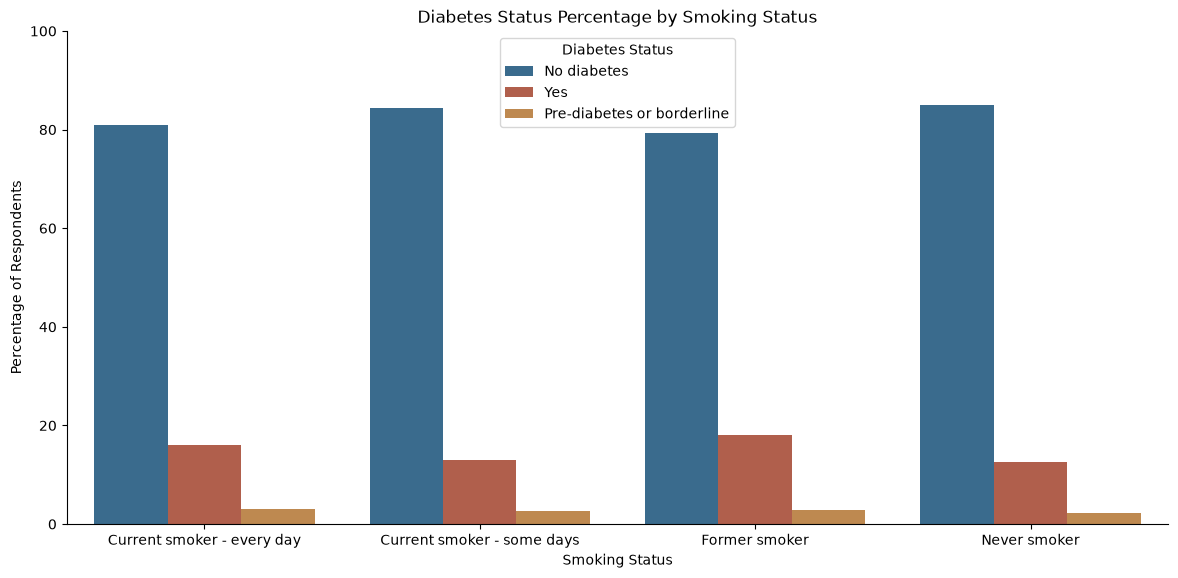

In [44]:
smoking_order = [
    "Current smoker - every day",
    "Current smoker - some days",
    "Former smoker",
    "Never smoker"
]

diabetes_order = [
    "No diabetes",
    "Yes",
    "Pre-diabetes or borderline"
]

smoking_df = df[
    df["smoking_status"].isin(smoking_order)
]

smoking_percentage_df = (
    smoking_df
    .groupby(["smoking_status", "diabetes_status"], observed=True)
    .size()
    .reset_index(name="count")
)

smoking_percentage_df["percentage"] = (
    smoking_percentage_df["count"] /
    smoking_percentage_df.groupby("smoking_status")["count"].transform("sum") * 100
)

# n per smoking group: count before you compare
print(smoking_df["smoking_status"].value_counts().reindex(smoking_order).to_string())

plt.figure(figsize=(12, 6))

sns.barplot(
    data=smoking_percentage_df,
    x="smoking_status",
    y="percentage",
    hue="diabetes_status",
    hue_order=diabetes_order,
    order=smoking_order,
    palette=["#2C6E9B", "#C1553B", "#D08A3E"]
)

plt.title("Diabetes Status Percentage by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Percentage of Respondents")
plt.ylim(0, 100)
plt.legend(title="Diabetes Status")
plt.tight_layout(pad=1.5)
plt.show()


**Conclusion.** The bars barely differ across smoking groups — the relationship is
weak, as the chi-square confirms. The faceted version of this chart was dropped: it
showed the same weak pattern from the other direction and added nothing.


### BMI by diabetes status
**Question:** the numeric×categorical pair the project is really about — does the BMI distribution shift with diabetes status?


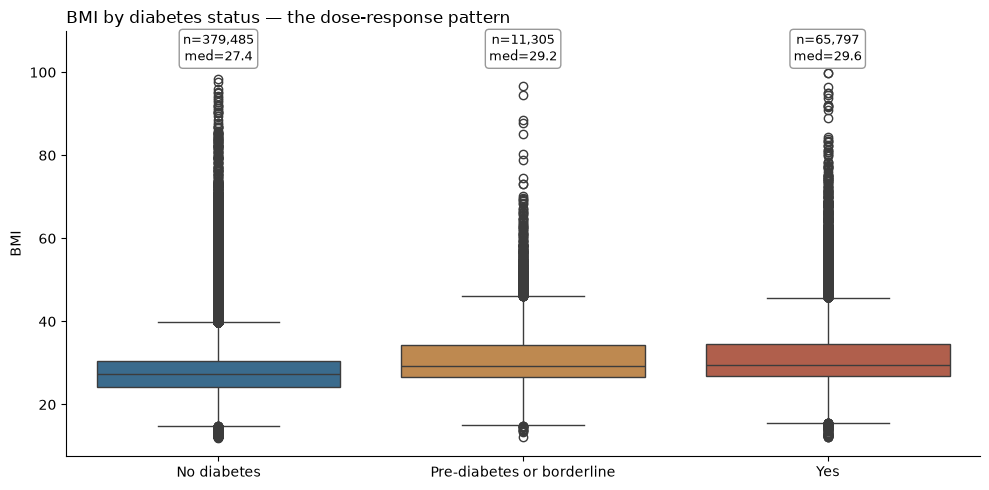

Decision: bmi stays a core feature — median rises monotonically across the three classes.


In [45]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(10, 5))
order = ["No diabetes", "Pre-diabetes or borderline", "Yes"]
sns.boxplot(data=df, x="diabetes_status", y="bmi", order=order, ax=ax,
            palette=["#2C6E9B", "#D08A3E", "#C1553B"])
ax.set_xlabel(""); ax.set_ylabel("BMI")
ax.set_title("BMI by diabetes status — the dose-response pattern", fontsize=12, loc="left")
# n/med labels go at the TOP, above the highest outlier — nothing to collide with up there
top = df["bmi"].max()
ax.set_ylim(None, top + 10)
for i, st in enumerate(order):
    s = df.loc[df["diabetes_status"] == st, "bmi"].dropna()
    ax.text(i, top + 2, f"n={len(s):,}\nmed={s.median():.1f}", ha="center", va="bottom",
            fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999"))
plt.tight_layout(); plt.show()
print("Decision: bmi stays a core feature — median rises monotonically across the three classes.")


**Conclusion.** Median BMI steps up cleanly across the three classes — a textbook
dose-response, and the n/med labels now sit clear of the outliers. BMI is the top
modifiable predictor in this file.


### BMI vs age — numeric×numeric
**Question:** are the two strongest numeric predictors redundant with each other?


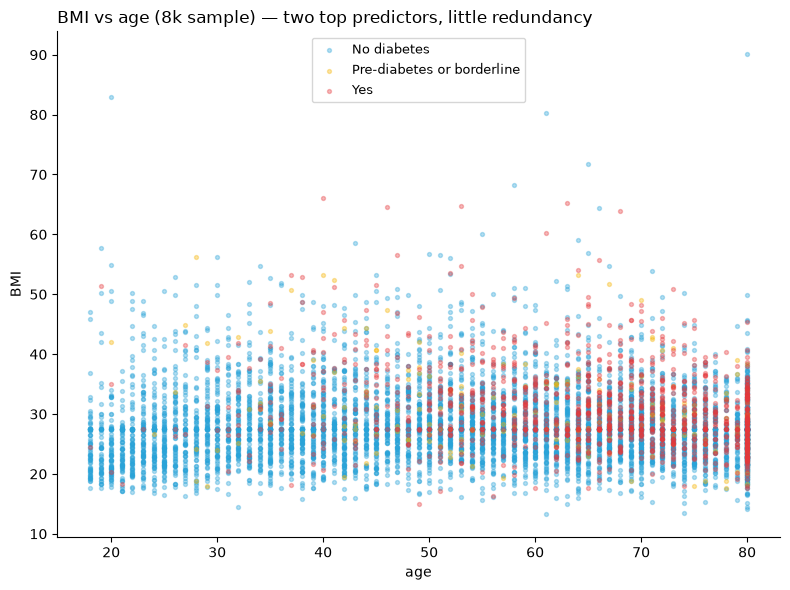

Pearson r(age, bmi)  = -0.013
Spearman r(age, bmi) = -0.013
Both near zero and agreeing -> no linear/monotone redundancy; keep both.


In [46]:
# Scatter: BMI vs age on an 8k sample (readable points), coloured by diabetes status.
samp = df.sample(8000, random_state=7)
fig, ax = plt.subplots(figsize=(8, 6))
for st, col in [("No diabetes", "#29A3D8"), ("Pre-diabetes or borderline", "#F5B301"),
                ("Yes", "#E5383B")]:
    d = samp[samp["diabetes_status"] == st]
    ax.scatter(d["age"], d["bmi"], s=8, alpha=0.35, color=col, label=st)
ax.set_xlabel("age"); ax.set_ylabel("BMI")
ax.set_title("BMI vs age (8k sample) — two top predictors, little redundancy",
             fontsize=12, loc="left"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
sub = df[["age", "bmi"]].dropna()
print(f"Pearson r(age, bmi)  = {sub['age'].corr(sub['bmi'], method='pearson'):.3f}")
print(f"Spearman r(age, bmi) = {sub['age'].corr(sub['bmi'], method='spearman'):.3f}")
print("Both near zero and agreeing -> no linear/monotone redundancy; keep both.")


**Conclusion.** Age and BMI barely move together (both correlations near zero), so
each carries its own signal — keep both. The brighter palette now separates the three
classes cleanly.


### Smoking × diabetes — chi-square
**Question:** is the smoking/diabetes association distinguishable from noise?


In [47]:
# Chi-square test: is the smoking x diabetes association stronger than chance?
from scipy.stats import chi2_contingency
ct = pd.crosstab(df["smoking_status"], df["diabetes_status"])
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.values.sum(); k = min(ct.shape)
cramers_v = (chi2 / (n * (k - 1))) ** 0.5
print(ct.to_string())
print(f"\nchi2 = {chi2:,.0f}, dof = {dof}, p ~ 0 (n = {n:,})")
print(f"Cramer's V = {cramers_v:.3f} — statistically decisive but a weak association.")
print("Decision: keep smoking_status; the former-smoker bump reflects quitting after")
print("diagnosis (reverse causation) — state it, don't overclaim.")


diabetes_status             No diabetes  Pre-diabetes or borderline    Yes
smoking_status                                                            
Current smoker - every day        26725                        1012   5282
Current smoker - some days        11741                         380   1804
Former smoker                     94570                        3300  21515
Never smoker                     219722                        5960  32772
Unknown                           26727                         653   4424

chi2 = 2,199, dof = 8, p ~ 0 (n = 456,587)
Cramer's V = 0.049 — statistically decisive but a weak association.
Decision: keep smoking_status; the former-smoker bump reflects quitting after
diagnosis (reverse causation) — state it, don't overclaim.


**Conclusion.** The smoking–diabetes link is real (p ~ 0) but tiny (Cramér's V ≈ 0.05):
worth keeping as a feature, not worth a causal story. Former smokers look worst because
a diagnosis is what makes people quit.


## Act 5 · Multivariate
**Question:** what is really driving diabetes once all numeric predictors are viewed together?
Diverging palette, zero at the centre.


### Reading the correlation heatmap — in detail
**What each cell means.** The Spearman correlation between two numeric predictors:
+1 = they rise together perfectly, −1 = one rises as the other falls, 0 = no steady
relationship. The diagonal is 1 (a variable with itself); the map mirrors across it.
**Why Spearman, not Pearson.** Spearman works on ranks, so the skew and outliers in our
variables don't distort it. Pearson would overreact to the long tails.
**How to read the colours.** Dark red = move together; dark blue = move apart;
pale/white = near-independent. Darker = stronger.
**The three dark blocks.** Drinking days/month × drinks/week = 0.98 — nearly the same
behaviour measured twice. Smoking cigarettes/day × pack-years = 0.96 — same habit,
pack-years just multiplies by duration. Body weight × BMI = 0.83 — expected, since BMI
is computed from weight.
**Everything else is pale (|r| ≤ 0.2).** BMI, age, drinking and smoking barely talk to
each other — no hidden redundancy to prune, so each carries its own signal into the model.
**Why diabetes itself isn't in this map.** Correlation needs numbers on both sides, but
`diabetes_status` is categorical (Yes / No / Pre-diabetes). Its relationships live in the
boxplots, the prevalence bars, and the age × gender heatmap below — different tools for a
different variable type.


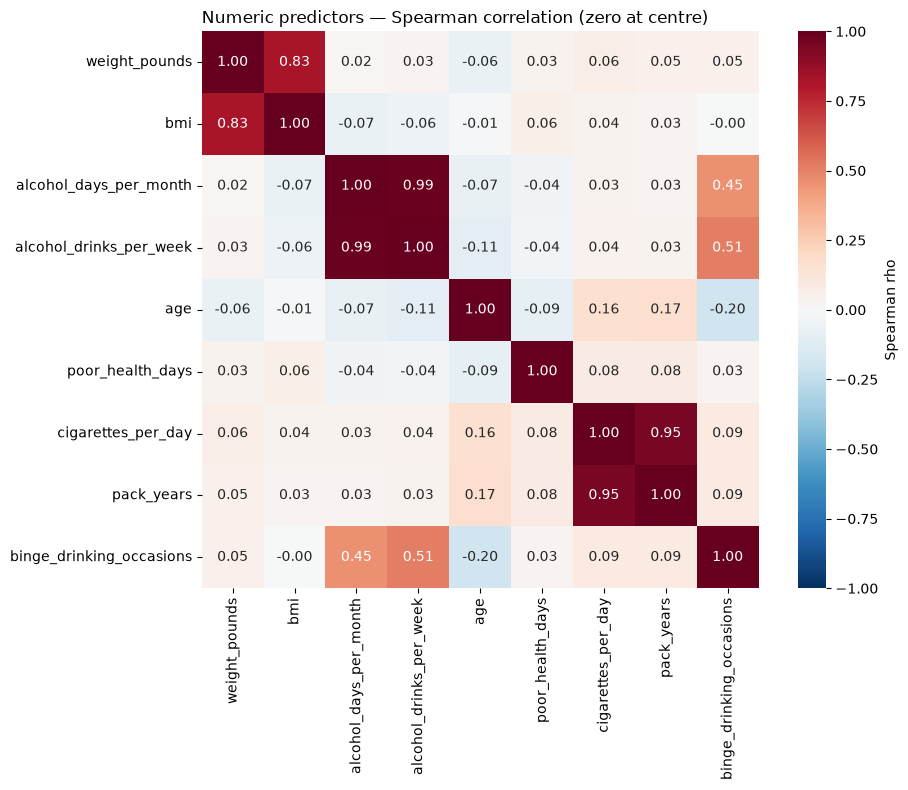

Read: the drinking block and the smoking block correlate with themselves;
bmi / age / drinking are near-independent — no redundancy to prune, but the
smoking twins should not both enter a linear model unpenalised.


In [48]:
# Spearman correlation heatmap of the numeric predictors (rank-based, safe with outliers).
corr = df[["weight_pounds", "bmi", "alcohol_days_per_month", "alcohol_drinks_per_week",
           "age", "poor_health_days", "cigarettes_per_day", "pack_years",
           "binge_drinking_occasions"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=ax, cbar_kws={"label": "Spearman rho"})
ax.set_title("Numeric predictors — Spearman correlation (zero at centre)",
             fontsize=12, loc="left")
plt.tight_layout(); plt.show()
print("Read: the drinking block and the smoking block correlate with themselves;")
print("bmi / age / drinking are near-independent — no redundancy to prune, but the")
print("smoking twins should not both enter a linear model unpenalised.")


**Conclusion.** Three near-duplicate pairs (drinking ×2, smoking ×2, weight × BMI)
and little else — the predictor set is refreshingly non-redundant. For a simple model,
pick one from each dark block.


### Heatmap 2 — diabetes prevalence by age x income
**Question:** the first heatmap couldn't include diabetes (it's categorical). This one
can: each cell is P(diabetes = Yes) for one age x income group — 13 age bands by 12
income bands, nearly square, so the two gradients are easy to compare at a glance.


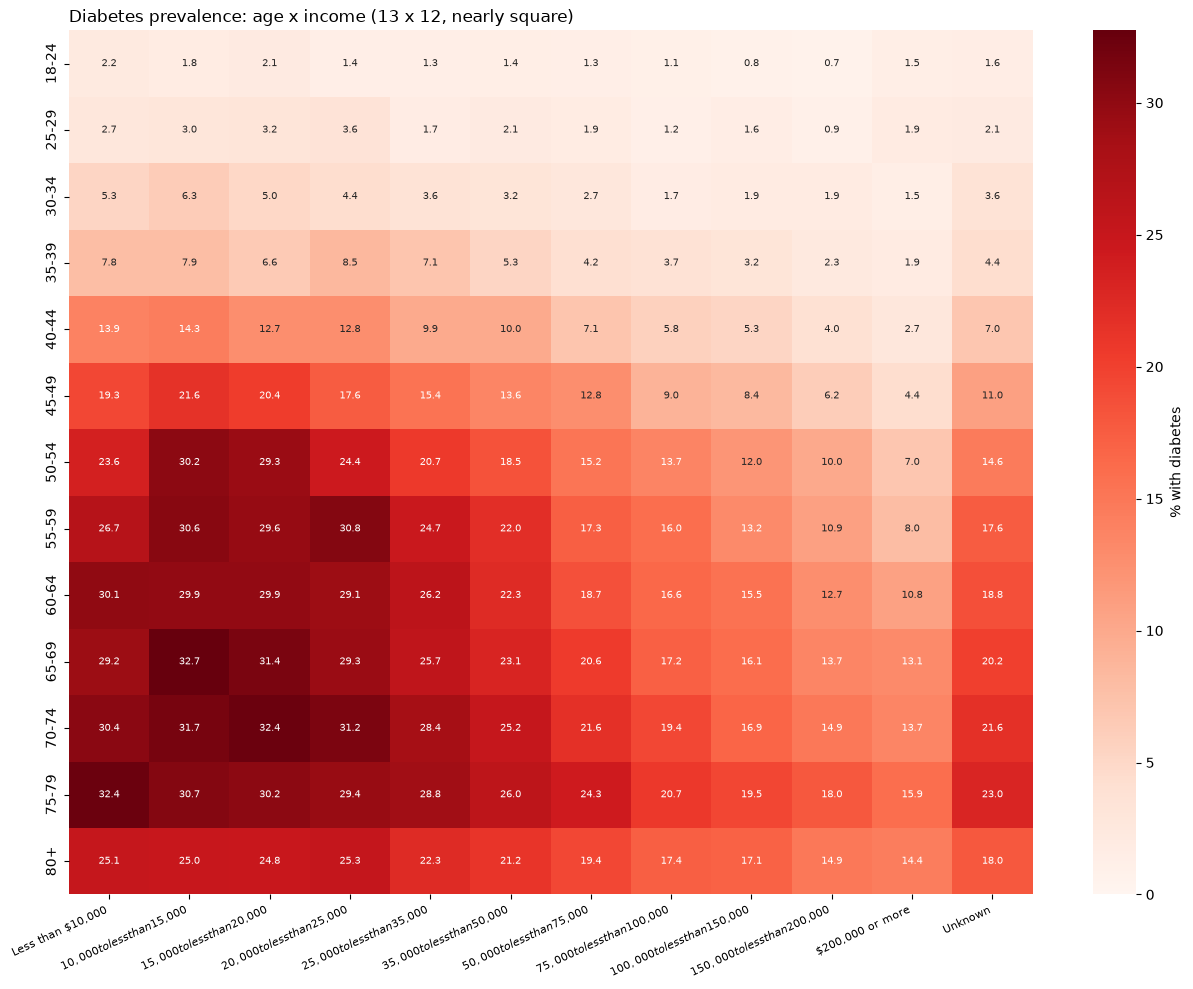

Highest cell: ('65-69', '$10,000 to less than $15,000') 32.7%
Lowest cell: ('18-24', '$150,000 to less than $200,000') 0.7%


In [49]:
# Prevalence heatmap: P(diabetes = Yes) for each of 13 age bands x 12 income bands.
age_order = ["18-24","25-29","30-34","35-39","40-44","45-49","50-54",
             "55-59","60-64","65-69","70-74","75-79","80+"]
inc_order = ["Less than $10,000", "$10,000 to less than $15,000",
             "$15,000 to less than $20,000", "$20,000 to less than $25,000",
             "$25,000 to less than $35,000", "$35,000 to less than $50,000",
             "$50,000 to less than $75,000", "$75,000 to less than $100,000",
             "$100,000 to less than $150,000", "$150,000 to less than $200,000",
             "$200,000 or more", "Unknown"]
mat = (pd.crosstab(df["age_group"], df["detailed_income_level"],
                   values=is_yes, aggfunc="mean")
         .reindex(index=age_order, columns=inc_order) * 100)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(mat, annot=True, fmt=".1f", annot_kws={"fontsize": 7}, cmap="Reds",
            vmin=0, ax=ax, cbar_kws={"label": "% with diabetes"})
ax.set_title("Diabetes prevalence: age x income (13 x 12, nearly square)",
             fontsize=12, loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right", fontsize=8)
plt.tight_layout(); plt.show()
flat = mat.stack()
print(f"Highest cell: {flat.idxmax()} {flat.max():.1f}%")
print(f"Lowest cell: {flat.idxmin()} {flat.min():.1f}%")


**Conclusion.** At every age band, diabetes falls as income rises — e.g. among
70–74 year-olds, roughly 31% below $20k vs 14% at $200k+. Age and income compound:
the old + low-income corner is the highest-risk cell on the map, young + high-income
the lowest.


## Act 6 · Decisions — what the next person needs
The EDA is done when every column has a verdict and the modelling plan is fixed.
Written plainly, so anyone on the team can follow it.

| What we found | What we did | Why, in plain words |
|---|---|---|
| The target has 3 groups, not 2 | Predict all 3; give the 2 small groups extra weight | Only 14.4% have diabetes and 2.5% pre-diabetes — without help, the model would just always guess "No" and look accurate |
| POORHLTH looked 42.6% missing | Kept it; filled the missing values with 0 | The survey only asks this question after a bad-health day, so "missing" really means zero bad days. This saved ~189k rows |
| Smoking and drinking intensity looked 54–68% missing | Kept them; filled with 0 for never-smokers and non-drinkers | A never-smoker truly smoked zero cigarettes — the question was skipped, not unanswered |
| Drinks-per-week looked 100× too big | Divided the column by 100 | The file stores it ×100 (two hidden decimals); without the fix every average was wrong |
| Soda questions, quit-smoking timing, pre-diabetes test recency | Dropped them | 67–75% missing, and the test-recency question would leak the answer (doctors test people they already suspect) |
| Tiny groups (daily vapers, "never had a checkup", ...) | Will merge them before modelling | An average over a handful of people is noise, not a finding |
| Twin columns saying the same thing | Kept both for charts; will drop one twin before modelling | Two income columns and two activity columns — the model only needs one of each |
| Filling nulls vs the target | Checked: filled rows ≈ observed rows | The fills add rows without pushing the diabetes rate up or down |
| BMI | Keep as a top feature | Heavier → more diabetes, step by step across all three groups |
| Age | Keep as a top feature | 1.4% at 18–24 → 24.1% at 75–79 |
| Smoking | Keep, but it is weak | Real link, tiny effect; ex-smokers look worse only because a diagnosis makes people quit |

**Preliminary ML direction (no model is fit in this notebook — on purpose).**
Predict `diabetes_status` (Yes / No diabetes / Pre-diabetes) from the demographic,
behavioural and healthcare-access columns above — a **multiclass classification**
problem, with class weights or resampling so the 14.4% and 2.5% groups aren't ignored.
December's grading is on interpretation (confusion matrix, ROC curves, feature
importance, SHAP), not raw accuracy.


In [50]:
# Save the cleaned table: 456,587 rows x 30 columns, ready for Tableau and modelling.
df.to_csv("brfss2024_diabetes_eda_clean.csv", index=False)
print(f"Saved brfss2024_diabetes_eda_clean.csv — {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Columns:", df.columns.tolist())


Saved brfss2024_diabetes_eda_clean.csv — 456,587 rows x 30 columns
Columns: ['diabetes_status', 'physical_activity', 'leisure_physical_activity', 'weight_pounds', 'bmi', 'bmi_category', 'smoked_100_cigarettes', 'smoking_status', 'smokeless_tobacco_use', 'e_cigarette_use', 'cigarettes_per_day', 'pack_years', 'alcohol_days_per_month', 'binge_drinking_occasions', 'alcohol_use_past_30_days', 'alcohol_drinks_per_week', 'heavy_alcohol_use', 'gender', 'age', 'age_group', 'education_level', 'detailed_income_level', 'income_group', 'marital_status', 'employment_status', 'race_ethnicity', 'general_health', 'poor_health_days', 'stroke_history', 'routine_checkup']
